In [1]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
import joblib
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
import pandas as pd
from scipy import signal
from scipy.ndimage import shift
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
from sklearn import tree
from sklearn import ensemble
from functools import reduce
import os
import coremltools
from scipy import stats
#regex module
import re
from collections import defaultdict
from scipy.spatial import distance
import itertools
from scipy.signal import argrelmin
import scipy.signal as signal
pattern = r'[0-9]'
# #original string
# string1 = "Hello!James12,India2020"

# 

# # Match all digits in the string and replace them with an empty string
# new_string = re.sub(pattern, '', string1)

TensorFlow version 2.15.0 has not been tested with coremltools. You may run into unexpected errors. TensorFlow 2.12.0 is the most recent version that has been tested.


Functions below for compiling segmenting./detecting and extracting features from signals

In [9]:
def Compile(filenames,template,distance=200,height=5.,prominence=1,plot=False,shot_length=2):
    n= len(filenames)
    for i in range(0,n):
        if i == 0: #AllfPitch, AllfRoll,AllfYaw   DfPitch, DfRoll,DfYaw
            AllfGyroX, AllfGyroY, AllfGyroZ,AllfAccelX, AllfAccelY, AllfAccelZ, AllfAccelTime,AllfPitch, AllfRoll,AllfYaw,Allname,Allshot,Allshots_made   = segment(filenames[i],prominence,distance,height,100,template,shot_length,True)
        else:
            DfGyroX, DfGyroY, DfGyroZ,DfAccelX, DfAccelY, DfAccelZ,DfGyroTime,DfPitch, DfRoll,DfYaw,Dname,Dshot,Dshots_made = segment(filenames[i],prominence,distance,height,100,template,shot_length,plot)
            AllfGyroX = np.hstack((AllfGyroX, DfGyroX))
            AllfGyroY = np.hstack((AllfGyroY, DfGyroY))
            AllfGyroZ = np.hstack((AllfGyroZ, DfGyroZ))
            AllfAccelX = np.hstack((AllfAccelX, DfAccelX))
            AllfAccelY = np.hstack((AllfAccelY, DfAccelY))
            AllfAccelZ = np.hstack((AllfAccelZ, DfAccelZ))
            AllfPitch = np.hstack((AllfPitch, DfPitch))
            AllfRoll = np.hstack((AllfRoll, DfRoll))
            AllfYaw = np.hstack((AllfYaw, DfYaw))
            Allname= np.hstack((Allname, Dname))
            Allshot= np.hstack((Allshot, Dshot))
            Allshots_made= np.hstack((Allshots_made, Dshots_made))
            # AllDDTW= np.vstack((AllDDTW, DDTW))
    # minmax= MinMaxScaler((0,10))
    # AllDDTW= minmax.fit_transform(AllDDTW)
    # max_distance_accel= np.max(AllDDTW[:,:3],axis=1)
    # max_distance_gyro= np.max(AllDDTW[:,3:],axis=1)
    # min_distance_accel= np.min(AllDDTW[:,:3],axis=1)
    # global min_distance_gyro
    # min_distance_gyro= np.min(AllDDTW[:,3:],axis=1)
    # diff_accel= max_distance_accel-min_distance_accel
    # diff_gyro= max_distance_gyro-min_distance_gyro
    # # Plot average ddtw distances with a diff figure for gyro, euler and accel data, for each player
    # df= pd.DataFrame(AllDDTW, columns=['X_Accel','Y_Accel','Z_Accel','X_Gyro','Y_Gyro','Z_Gyro'])
    # df= pd.concat([df,pd.DataFrame(Allname,columns=['Name'])],axis=1)
    # fig, axs = plt.subplots(1, 1)
    # # fig2, axs2 = plt.subplots(1, 1)
    # fig3, axs3 = plt.subplots(1, 1)
    # axs.title.set_text('Acceleration')
    # # axs2.title.set_text('Rotation')
    # axs3.title.set_text('Gyro')
    # colors= itertools.cycle(["r", "b", "g","y","m","c"])
    # color_dict = {}
    # for player in np.unique(Allname):
    #     df_player= df[df['Name']==player]
    #     for i in range(3):
    #         col = color_dict.get(i, next(colors))
    #         color_dict[i] = col
    #         axs.scatter(player,10-df_player.iloc[:,i].mean(),c=col)
    #         # axs2.scatter(player,df_player.iloc[:,i+6].mean(),c=col)
    #         axs3.scatter(player,10-df_player.iloc[:,i+3].mean(),c=col)
    # axs.legend(['X','Y','Z'])
    # # axs2.legend(['Pitch','Roll','Yaw'])
    # axs3.legend(['X','Y','Z'])
    # plt.show()
    return AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,AllfPitch, AllfRoll,AllfYaw,Allname,Allshot,Allshots_made
def plot_Axis(axis_array,axis_names,title):
    colors= itertools.cycle(["r", "b", "g","y","m","c"])
    color_dict = {}
    col = color_dict.get(i, next(colors))  # Get the color for the player from the dictionary or assign a new color
    color_dict[i] = col  # 
    fig, axs = plt.subplots(1, axis_names.shape[0], figsize=(15, 5))
    fig.suptitle(f'{title} in time domain')
    for i in range(axis_names.shape[0]):
        col = color_dict.get(i, next(colors))  # Get the color for the player from the dictionary or assign a new color
        color_dict[i] = col  # 
        axs[i].scatter(axis_array[i])
        axs[i].set_title(axis_names[i])
    plt.show()
def set_legend(ax):
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(),bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
# Compiling dishas shots- different parameters for segmentation and detection
def Compile_disha(filenames,distance=256,height=3,prominence=1,plot=False):
    n= len(filenames)
    for i in range(0,n):
        if i == 0:
            AllfGyroX, AllfGyroY, AllfGyroZ,AllfAccelX, AllfAccelY, AllfAccelZ, AllfAccelTime = segment_disha(filenames[i],prominence,distance,height,128,plot=True)
        else:
            DfGyroX, DfGyroY, DfGyroZ,DfAccelX, DfAccelY, DfAccelZ, DfGyroTime = segment_disha(filenames[i],prominence,distance,height,128,plot=False)
            AllfGyroX = np.hstack((AllfGyroX, DfGyroX))
            AllfGyroY = np.hstack((AllfGyroY, DfGyroY))
            AllfGyroZ = np.hstack((AllfGyroZ, DfGyroZ))
            AllfAccelX = np.hstack((AllfAccelX, DfAccelX))
            AllfAccelY = np.hstack((AllfAccelY, DfAccelY))
            AllfAccelZ = np.hstack((AllfAccelZ, DfAccelZ))

    return AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ

def segment_disha(Filename,prominence, distance, height,frequency,plot):
    """
    Segments the accelerometer data into separate shots based on gyro data peaks.

    Parameters:
    bData (str): The path to the CSV file containing the accelerometer data.

    Returns:
    SignalX_Accel (ndarray): Array containing the X-axis acceleration data for each shot.
    SignalY_Accel (ndarray): Array containing the Y-axis acceleration data for each shot.
    SignalZ_Accel (ndarray): Array containing the Z-axis acceleration data for each shot.
    SignalTime (ndarray): Array containing the time domain data for each shot.
    """
    # Function code goes here
#Convert CSV file to pandas then numpy array
    # bData = np.genfromtxt(bData, delimiter=',', skip_header=1)
    global file
    file= pd.read_csv(Filename)
    # Backhand data set
    bData = file.to_numpy()
    # scaler = StandardScaler()
    # bData = scaler.fit_transform(bData)
    bPacketNumber = np.arange(0,len(bData[:, 0]))
    f= frequency # because the frequency used is 128Hz
    bTimedomain = bPacketNumber / f   # because the frequency used is 128Hz
   
    bGyroX = np.deg2rad(bData[:, 1])
    bGyroY = np.deg2rad(bData[:, 2]*-1)
    bGyroZ = np.deg2rad(bData[:, 3])
    bAccelerationX = bData[:, 4]*9.81
    bAccelerationY = bData[:, 5]*-9.81
    bAccelerationZ = bData[:, 6]*9.81
    windowSize = 5
    bAccelMean = np.sqrt((bAccelerationX**2) + (bAccelerationY**2) + (bAccelerationZ**2))  # absolute magnitude accel
    bAccelMeanMovav = np.convolve(bAccelMean, np.ones(windowSize), 'valid') / windowSize  # moving average backhand
    bGyroMean = np.sqrt((bGyroX**2) + (bGyroY**2) + (bGyroZ**2))  # absolute magnitude gyro
    bMeanMovav = np.convolve(bGyroMean, np.ones(windowSize), 'valid') / windowSize  # moving average backh
    bpks, _ = find_peaks(bMeanMovav, prominence=prominence, distance=distance, height=height)  # peak distance of 2s and min peak height of .600

    bpks= np.array([bpks[i] for i in range(len(bpks)) if bAccelMeanMovav[bpks[i]]>30])
    if plot:
        plt.figure()
        plt.ylabel('Gyroscope Magnitude ')
        plt.plot(np.arange(0, len(bMeanMovav))/f, bMeanMovav)
        plt.scatter(bpks/f,bMeanMovav[bpks],c="r",label='Peaks')
        plt.xlabel('Time (s)')  # x-axis label
                # Plotting the prominence value also
        
        
        # plt.axhline(y=height, linestyle='--', color='#3CB371',label='Minimum Magnitude')
        # plt.legend()
        # plt.figure()
        # plt.ylabel('Accel magnitude (�/s)')
        # plt.plot(np.arange(0, len(bAccelMeanMovav))/f, bAccelMeanMovav)
        # plt.scatter(bpks/f,bMeanMovav[bpks],c="r")
        # plt.xlabel('Time (s)')  # x-axis label
    shot_len = 2 # seconds
  
    size = int(shot_len*f)
    # Saving each shot into separate column of one big array
    # shot length is assumed to be 5s in length
    SignalTime = np.zeros((size, len(bpks)))
    SignalX_Accel = np.zeros((size, len(bpks)))
    SignalY_Accel = np.zeros((size, len(bpks)))
    SignalZ_Accel = np.zeros((size, len(bpks)))
    SignalX_Gyro = np.zeros((size, len(bpks)))
    SignalY_Gyro = np.zeros((size, len(bpks)))
    SignalZ_Gyro = np.zeros((size, len(bpks)))
    print(SignalTime.shape)
    half_shot= int(size/2)
    for j in range(len(bpks)):
        timeIndex = bpks[j]  # select  time value of peak
        if timeIndex-half_shot<0:
            startSignal=0
        elif timeIndex+half_shot>len(bTimedomain):
            startSignal= len(bTimedomain)-size
        else:
            startSignal = timeIndex - half_shot
        # startSignal = np.max((0,timeIndex - half_shot))# subtract 2.5s worth of data points from peak to obtain time when shot begins
        endSignal = startSignal + size
        # SignalTime[:, j] = bTimedomain[startSignal:endSignal]  # 1 shot in time index to be saved in Signal matrix
        SignalX_Gyro[:endSignal, j] = bGyroX[startSignal:endSignal]
        SignalY_Gyro[:endSignal, j] = bGyroY[startSignal:endSignal]
        SignalZ_Gyro[:endSignal, j] = bGyroZ[startSignal:endSignal]
        SignalX_Accel[:endSignal, j] = bAccelerationX[startSignal:endSignal]
        SignalY_Accel[:endSignal, j] = bAccelerationY[startSignal:endSignal]
        SignalZ_Accel[:endSignal, j] = bAccelerationZ[startSignal:endSignal]

    global DDTW_distance
    DDTW_distance= np.zeros((len(bpks),6))
    # SignalX_Gyro= signal.resample(SignalX_Gyro, 250, axis=0)
    # SignalY_Gyro= signal.resample(SignalY_Gyro, 250, axis=0)
    # SignalZ_Gyro= signal.resample(SignalZ_Gyro, 250, axis=0)
    # SignalX_Accel= signal.resample(SignalX_Accel, 250, axis=0)
    # SignalY_Accel= signal.resample(SignalY_Accel, 250, axis=0)
    # SignalZ_Accel= signal.resample(SignalZ_Accel, 250, axis=0)
    #normalise the yaw pitch and roll values v=
    # plt.figure()
    # fig, axs = plt.subplots()
    # fig2, axs2 = plt.subplots()
    # fig3, axs3 = plt.subplots()
    # axs.title.set_text('a_x')
    # axs2.title.set_text('a_y')
    # axs3.title.set_text('a_z')
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     axs.plot(SignalX_Accel[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
    #     axs2.plot(SignalY_Accel[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
    #     axs3.plot(SignalZ_Accel[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
    # plt.xlabel('Time (s)')  # x-axis label
    # plt.ylabel('Acceleration (�/s)')  # y-axis label


    #Uncomment the following lines if you want to plot the data
    # plt.figure()
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     plt.plot(SignalX_Accel[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
    #     plt.xlabel('Time (s)')  # x-axis label
    #     plt.ylabel('Acceleration (g)')  # y-axis label
    #     plt.title('X Acceleration in Time Domain')
    # plt.figure()
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     plt.plot(SignalY_Accel[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
    #     plt.xlabel('Time (s)')  # x-axis label
    #     plt.ylabel('Acceleration (g)')  # y-axis label
    #     plt.title('Y Acceleration in Time Domain')
    # plt.figure()
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     plt.plot(SignalZ_Accel[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
    #     plt.xlabel('Time (s)')  # x-axis label

    #     plt.ylabel('Acceleration (g)')  # y-axis label
    #     plt.title('Z Acceleration in Time Domain')
    # plt.show()
    # plt.close()
    return SignalX_Gyro,SignalY_Gyro,SignalZ_Gyro,SignalX_Accel, SignalY_Accel, SignalZ_Accel, SignalTime

def segment(Filename,prominence, distance, height,frequency,template,shot_length=2,plot=True):
    """
    Segments the accelerometer data into separate shots based on gyro data peaks.

    Parameters:
    bData (str): The path to the CSV file containing the accelerometer data.

    Returns:
    SignalX_Accel (ndarray): Array containing the X-axis acceleration data for each shot.
    SignalY_Accel (ndarray): Array containing the Y-axis acceleration data for each shot.
    SignalZ_Accel (ndarray): Array containing the Z-axis acceleration data for each shot.
    SignalTime (ndarray): Array containing the time domain data for each shot.
    """
    # Function code goes here
    #Convert CSV file to pandas then numpy array
    # bData = np.genfromtxt(bData, delimiter=',', skip_header=1)
    global pattern
    file= pd.read_csv(Filename)
    # Backhand data set
    bData = file.to_numpy()
    # scaler = StandardScaler()
    # bData = scaler.fit_transform(bData)
    bPacketNumber = np.arange(0,len(bData[:, 0]))
    print(bPacketNumber)
    f= frequency # because the frequency used is 128Hz
    bTimedomain = bPacketNumber / f   # because the frequency used is 128Hz
    shot= Filename.split('Watch Sensor/')[1].split('_')[0]
    shots_made=  Filename.split('Watch Sensor')[1].split('/Motion')[0].split(shot+'_')[1].split('_')[0]
    name= Filename.split('Watch Sensor')[1].split('/Motion')[0].split(shot+'_')[1].split('_')[1]
    #some motion csv were named like shottype_shotsmade_name2.. name3, if it was the same multiple of shot for the same shot type
    #So take awya the numbers
    name= re.sub(pattern, '', name)
    windowSize = 10
    bGyroX = bData[:, 4]
    bGyroY = bData[:, 5]
    bGyroZ = bData[:, 6]
    bAccelerationX = bData[:, 1]
    bAccelerationY = bData[:, 2]
    bAccelerationZ = bData[:, 3]
    bAccelMean = np.sqrt((bAccelerationX**2) + (bAccelerationY**2) + (bAccelerationZ**2))  # absolute magnitude accel
    bAccelMeanMovav = np.convolve(bAccelMean, np.ones(windowSize), 'valid') / windowSize  # moving average backhand
    bGyroMean = np.sqrt((bGyroX**2) + (bGyroY**2) + (bGyroZ**2))  # absolute magnitude gyro
    bMeanMovav = np.convolve(bGyroMean, np.ones(windowSize), 'valid') / windowSize  # moving average backhand
    bPitch= bData[:, 10]
    bRoll= bData[:, 11]
    bYaw= bData[:, 12]
    print(f'{Filename}')
    bpks, _ = find_peaks(bMeanMovav, prominence=prominence, distance=distance, height=height)  # peak distance of 2s and min peak height of .600
    #check if acceleration magnitude is above 2, from data this should be true for even the weakest shots. It seperates non shot actions
    bpks= np.array([bpks[i] for i in range(len(bpks)) if bAccelMeanMovav[bpks[i]]>1.5])
    if plot:
        plt.figure()
        plt.ylabel('Gyroscope Magnitude ')
        plt.plot(np.arange(0, len(bMeanMovav))/f, bMeanMovav)
        plt.scatter(bpks/f,bMeanMovav[bpks],c="r",label='Peaks')
        plt.xlabel('Time (s)')  # x-axis label
                # Plotting the prominence value also
        plt.title(f'Shots detected from Gyroscope Moving average')
        
        plt.axhline(y=height, linestyle='--', color='#3CB371',label='Minimum Magnitude')
        plt.legend()
        plt.figure()
        plt.ylabel('Accel magnitude (�/s)')
        plt.plot(np.arange(0, len(bAccelMeanMovav))/f, bAccelMeanMovav)
        plt.scatter(bpks/f,bMeanMovav[bpks],c="r")
        plt.xlabel('Time (s)')  # x-axis label
      # y-axis label
    shot_len = shot_length # seconds
  
    size = int(shot_len*f)
    # Saving each shot into separate column of one big array
    # shot length is assumed to be 2.5s in length
    SignalTime = np.zeros((size, len(bpks)))
    SignalX_Accel = np.zeros((size, len(bpks)))
    SignalY_Accel = np.zeros((size, len(bpks)))
    SignalZ_Accel = np.zeros((size, len(bpks)))
    SignalX_Gyro = np.zeros((size, len(bpks)))
    SignalY_Gyro = np.zeros((size, len(bpks)))
    SignalZ_Gyro = np.zeros((size, len(bpks)))
    Signal_pitch= np.zeros((size, len(bpks)))
    Signal_roll= np.zeros((size, len(bpks)))
    Signal_yaw= np.zeros((size, len(bpks)))
    print(SignalTime.shape)
    half_shot= int(size/2)
    for j in range(len(bpks)):
        timeIndex = bpks[j]  # select first time value of peak
        startSignal = np.max((0,timeIndex - half_shot))# subtract 2.5s worth of data points from peak to obtain time when shot begins
        endSignal = np.min((timeIndex + half_shot,len(bTimedomain)))# add 2.5s worth of data points from peak to obtain end of signal
        # SignalTime[:, j] = bTimedomain[startSignal:endSignal]  # 1 shot in time index to be saved in Signal matrix
        SignalX_Gyro[:, j] = bGyroX[startSignal:endSignal]
        SignalY_Gyro[:, j] = bGyroY[startSignal:endSignal]
        SignalZ_Gyro[:, j] = bGyroZ[startSignal:endSignal]
        SignalX_Accel[:, j] = bAccelerationX[startSignal:endSignal]
        SignalY_Accel[:, j] = bAccelerationY[startSignal:endSignal]
        SignalZ_Accel[:, j] = bAccelerationZ[startSignal:endSignal]
        Signal_pitch[:, j] = bPitch[startSignal:endSignal]
        Signal_roll[:, j] = bRoll[startSignal:endSignal]
        Signal_yaw[:, j] = bYaw[startSignal:endSignal]
        #normalise the yaw pitch and roll values by their starting value since we dont care about teh absolute
        #only the change in rotation
        Signal_pitch[:, j] = Signal_pitch[:, j] - Signal_pitch[0, j]
        Signal_roll[:, j] = Signal_roll[:, j] - Signal_roll[0, j]
        Signal_yaw[:, j] = Signal_yaw[:, j] - Signal_yaw[0, j]
    
    #convert to degrees
    Signal_pitch= np.degrees(Signal_pitch)
    Signal_roll= np.degrees(Signal_roll)
    Signal_yaw= np.degrees(Signal_yaw)
    # global DDTW_distance
    DDTW_distance= np.zeros((len(bpks),6))
    # # #Align signals and get and plot ddtw distances for each shot and axis showig the player also
    # for i in range(1,len(bpks)):
    #     SignalX_Accel[:,i],DDTW_distance[i,0]= fast_ddtw(SignalX_Accel[:,i],SignalX_Accel[:,i-1])
    #     SignalY_Accel[:,i],DDTW_distance[i,1]= fast_ddtw(SignalY_Accel[:,i],SignalY_Accel[:,i-1])
    #     SignalZ_Accel[:,i],DDTW_distance[i,2]= fast_ddtw(SignalZ_Accel[:,i],SignalZ_Accel[:,i-1])
    #     SignalX_Gyro[:,i],DDTW_distance[i,3]= fast_ddtw(SignalX_Gyro[:,i],SignalX_Gyro[:,i-1])
    #     SignalY_Gyro[:,i],DDTW_distance[i,4]= fast_ddtw(SignalY_Gyro[:,i],SignalY_Gyro[:,i-1])   
    #     SignalZ_Gyro[:,i],DDTW_distance[i,5]= fast_ddtw(SignalZ_Gyro[:,i],SignalZ_Gyro[:,i-1])
        # Signal_pitch[:,i],DDTW_distance[i,6]= fast_ddtw(Signal_pitch[:,i],Signal_pitch[:,i-1])
    #     # Signal_roll[:,i],DDTW_distance[i,7]= fast_ddtw(Signal_roll[:,i],template[7])
    #     # Signal_yaw[:,i],DDTW_distance[i,8]= fast_ddtw(Signal_yaw[:,i],template[8])
    # # # player= [f'{name}']len(
    # # average distance 
    # DDTW_average= [stats.trim_mean(DDTW_distance[i],0.1) for i in range(len(bpks))]
    # df= pd.DataFrame({'Distance':DDTW_average,'Player':name,'Shot':shot})
    # # append to global dictiorary
    # global DDTW_distances
    # DDTW_distances= pd.concat([DDTW_distances,df])

    # plt.figure()
    # fig, axs = plt.subplots()
    # fig2, axs2 = plt.subplots()
    # fig3, axs3 = plt.subplots()
    # axs.title.set_text('a_x')
    # axs2.title.set_text('a_y')
    # axs3.title.set_text('a_z')
    # for plotIdx in range(SignalX_Accel.shape[1]):
    #     axs.plot(SignalX_Accel[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
    #     axs2.plot(SignalY_Accel[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
    #     axs3.plot(SignalZ_Accel[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
    # plt.xlabel('Time (s)')  # x-axis label
    # plt.ylabel('Acceleration (�/s)')  # y-axis label


    # Uncomment the following lines if you want to plot the data
    # if shot == 'Serve':
    #     plt.figure()
    #     for plotIdx in range(SignalX_Accel.shape[1]):
    #         plt.plot(SignalX_Accel[:, plotIdx], 'r')  # overlay all forehand shots onto 1 curve
    #         plt.xlabel('Time (s)')  # x-axis label
    #         plt.ylabel('Acceleration (g)')  # y-axis label
    #         plt.title(f'{name} {shots_made} shots X Acceleration in Time Domain')
    #     plt.figure()
    #     for plotIdx in range(SignalX_Accel.shape[1]):
    #         plt.plot(SignalY_Accel[:, plotIdx], 'g')  # overlay all forehand shots onto 1 curve
    #         plt.xlabel('Time (s)')  # x-axis label
    #         plt.ylabel('Acceleration (g)')  # y-axis label
    #         plt.title('Y Acceleration in Time Domain')
    #     plt.figure()
    #     for plotIdx in range(SignalX_Accel.shape[1]):
    #         plt.plot(SignalZ_Accel[:, plotIdx], 'b')  # overlay all forehand shots onto 1 curve
    #         plt.xlabel('Time (s)')  # x-axis label

    #         plt.ylabel('Acceleration (g)')  # y-axis label
    #         plt.title('Z Acceleration in Time Domain')
    #     plt.show()
    #     # Same for gyhro data
    #     plt.figure()
    #     for plotIdx in range(SignalX_Gyro.shape[1]):
    #         plt.plot(SignalX_Gyro[:, plotIdx], 'r')
    #         plt.xlabel('Time (s)')  # x-axis label
    #         plt.ylabel('Gyro (�/s)')  # y-axis label
    #         plt.title('X Gyro in Time Domain')
    #     plt.figure()
    #     for plotIdx in range(SignalX_Gyro.shape[1]):
    #         plt.plot(SignalY_Gyro[:, plotIdx], 'g')
    #         plt.xlabel('Time (s)')
    #         plt.ylabel('Gyro (�/s)')
    #         plt.title('Y Gyro in Time Domain')
    #     plt.figure()
    #     for plotIdx in range(SignalX_Gyro.shape[1]):
    #         plt.plot(SignalZ_Gyro[:, plotIdx], 'b')
    #         plt.xlabel('Time (s)')
    #         plt.ylabel('Gyro (�/s)')
    #         plt.title('Z Gyro in Time Domain')
    #     plt.show()
    return SignalX_Gyro,SignalY_Gyro,SignalZ_Gyro,SignalX_Accel, SignalY_Accel, SignalZ_Accel, SignalTime ,Signal_pitch,Signal_roll,Signal_yaw,[name]*len(bpks),shot,int(shots_made)#,DDTW_distance

def smoothcurve(Sign1,Sign2,Sign3,names,length,title,num_shots,shot):
    players_smoothness= np.zeros((3,num_shots))
    windowSize=5
    Sig1= np.zeros((Sign1.shape[0]-windowSize+1,num_shots))
    Sig2= np.zeros((Sign1.shape[0]-windowSize+1,num_shots))
    Sig3= np.zeros((Sign1.shape[0]-windowSize+1,num_shots))
    for i in range(num_shots):
        Sig1[:,i]= np.convolve(Sign1[:,i], np.ones(windowSize), 'valid') / windowSize 
        Sig2[:,i]= np.convolve(Sign2[:,i], np.ones(windowSize), 'valid') / windowSize
        Sig3[:,i]= np.convolve(Sign3[:,i], np.ones(windowSize), 'valid') / windowSize
    print(Sig1.shape)
    standard= StandardScaler()
    Sig1= standard.fit_transform(Sig1)
    Sig2= standard.fit_transform(Sig2)
    Sig3= standard.fit_transform(Sig3)
    for i in range(num_shots):
        players_smoothness[0,i]= np.abs(np.std(np.diff(Sig1[length:-60,i])).round(2))
        players_smoothness[1,i]= np.abs(np.std(np.diff(Sig2[length:-60,i])).round(2))
        players_smoothness[2,i]= np.abs(np.std(np.diff(Sig3[length:-60,i])).round(2))
    minmax= MinMaxScaler((0,10))

    # players_smoothness= minmax.fit_transform(players_smoothness.T).T
    #global eval('title[]')
    #unique values in title
    color_dict= {f'{names[0]}':'r',f'{names[1]}':'b',f'{names[2]}':'g'}
    fig,ax= plt.subplots(1,1)
    fig.suptitle(f'Smoothness for {np.unique(shot)[0]} with {250-length} samples')
    fig_avg,ax_avg= plt.subplots(1,1)
    fig_avg.suptitle(f'Average Smoothness for {np.unique(shot)[0]} with {250-length} samples')
    for player in players:
        player_smoothness=players_smoothness[:,title==player]
        player_shots= len(player_smoothness[0,:])
        x_values = [player] * player_shots
        if player_shots>0:
            ax.scatter(x_values,player_smoothness[0],c=color_dict.get(f'{names[0]}'))
            ax.scatter(x_values,player_smoothness[1],c=color_dict.get(f'{names[1]}'))
            ax.scatter(x_values,player_smoothness[2],c=color_dict.get(f'{names[2]}'))
            ax_avg.scatter(player, stats.trim_mean(player_smoothness[0],0.1),c=color_dict.get(f'{names[0]}'))
            ax_avg.scatter(player, stats.trim_mean(player_smoothness[1],0.1),c=color_dict.get(f'{names[1]}'))
            ax_avg.scatter(player, stats.trim_mean(player_smoothness[2],0.1),c=color_dict.get(f'{names[2]}'))
    ax.set_xlabel('Player')
    ax.set_ylabel('Smoothness')
    ax.legend(names)
    ax_avg.set_xlabel('Player')
    ax_avg.set_ylabel('Smoothness')
    ax_avg.legend(names)
    plt.show()
    
def feature_template(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,title, AllSignal_pitch, AllSignal_roll,AllSignal_yaw,shot,shot_template):
    # Angular Velocities
    AllfGyro_av = np.mean([AllfGyroX + AllfGyroY + AllfGyroZ], axis=0)
    # print(AllfGyro_av.shape[0])
    num_shots= AllfGyroX.shape[1]

    # Racket linear speed
    R = 0.7445  # radius from shoulder to point of impact of ball
    Maxes = np.max(np.abs(AllfGyro_av), axis=0)
    Peaky = Maxes[1]
    Peakz = Maxes[2]
    omega = np.sqrt((Peaky * 0.0174533) ** 2 + (Peakz * 0.0174533) ** 2)
    LinSpeed = omega * R
    print(f'Linear Speed: {LinSpeed}')

    # Spin Rating
    maxiY = np.max(np.abs(AllfGyroY))
    maxY = np.max(maxiY)
    minY = np.min(maxiY)
    maxiZ = np.max(np.abs(AllfGyroZ))
    maxZ = np.max(maxiZ)
    minZ = np.min(maxiZ)
    if maxiY.size > 0 and maxiZ.size > 0:
        omega_high = np.sqrt(maxY ** 2 + maxZ ** 2)
        omega_low = np.sqrt(minY ** 2 + minZ ** 2)
        theta_high = omega_high * 0.12
        theta_low = omega_low * 0.12
    else:
        theta_high = 0
        theta_low = 0
    # Plotting
    # plt.figure()
    # plt.plot(AllfGyro_av[0, :], 'r', linewidth=1.5)
    # plt.plot(AllfGyro_av[1, :], 'g', linewidth=1.5)
    # plt.plot(AllfGyro_av[2, :], 'b', linewidth=1.5)
    # plt.legend(['\omega_x', '\omega_y', '\omega_z'])
    # plt.xlabel('Time (s)')  # x-axis label
    # plt.ylabel('Gyroscope (°/s)')  # y-axis label

    # Acceleration mag for Power Rating
    AllfAccel_av = np.mean([AllfAccelX+ AllfAccelY + AllfAccelZ], axis=0)
    MagAccel = np.sqrt(AllfAccelZ ** 2)  # magnitude of acceleration for all shots
    MagAccelPeaks = MagAccel[229:237, :]
    MagAccelmeans = np.mean(MagAccelPeaks, axis=0)
    if MagAccelmeans.size > 0:
        magA_low = np.min(MagAccelmeans[:], axis=0)
        magA_high = np.max(MagAccelmeans[:])
    else:
        magA_low = 0
        magA_high = 0
    # #   Calculater euclidean distance for shots
    # std_scale= StandardScaler()
    # global Accel_template
    # Accel_template = shot_template[:, :3]
    # Gyro_template = shot_template[:, 3:6]
    # # euler_template= shot_template[:, 6:]
    # player_Accel = np.array([std_scale.fit_transform(AllfAccelX), std_scale.fit_transform(AllfAccelY), std_scale.fit_transform(AllfAccelZ)])
    # player_Gyro = np.array([std_scale.fit_transform(AllfGyroX),std_scale.fit_transform(AllfGyroY), std_scale.fit_transform(AllfGyroZ)])
    # Accel_template = std_scale.fit_transform(Accel_template)
    # Gyro_template = std_scale.fit_transform(Gyro_template)
    # player_euler= np.array([AllSignal_pitch, AllSignal_roll,AllSignal_yaw])
    # player_Accel = np.transpose(player_Accel, (1, 0, 2))
    # player_Gyro = np.transpose(player_Gyro, (1, 0, 2))
    # player_euler = np.transpose(player_euler, (1, 0, 2))
    # # calculate distance for each axis
    # global distance_Accel
    # distance_Accel= np.zeros((player_Accel.shape[1], num_shots))
    # distance_Gyro= np.zeros((player_Gyro.shape[1], num_shots))
    # for i in range(num_shots):
    #     for j in range(3):
    #         distance_Accel[j,i] = distance.euclidean(player_Accel[:,j,i], Accel_template[:,j])
    #         distance_Gyro[j,i] = distance.euclidean(player_Gyro[:,j,i], Gyro_template[:,j])
    # # print(np.unique(shot))
    # print(np.max(distance_Accel))
    # print(np.max(distance_Gyro))
    # print(np.min(distance_Accel))
    # print(np.min(distance_Gyro))
    # global errors
    # # plot the different euclidean distances for each player
    # global players
    # fig1, ax1 = plt.subplots(1, 1)
    # fig2, ax2 = plt.subplots(1, 1)
    # fig_avgacc, ax_avgaccel = plt.subplots(1, 1)
    # fig_avggyr, ax_gyro = plt.subplots(1, 1)
    # fig1.suptitle(f'Euclidean distance/quality for {np.unique(shot)}')
    # fig2.suptitle(f'Euclidean distance/quality for {np.unique(shot)}')
    # fig_avgacc.suptitle(f'Average Euclidean distance/quality  for {np.unique(shot)}')
    # fig_avggyr.suptitle(f'Average Euclidean distance/quality  for {np.unique(shot)}')
    # ax1.set_title('Acceleration')
    # ax2.set_title('Gyroscope')
    # ax_avgaccel.set_title('Acceleration')
    # ax_gyro.set_title('Gyroscope')
    # colors = itertools.cycle(["r", "b", "g"])
    # color_dict = {}  # Initialize the color dictionary
    # minmax= MinMaxScaler((0,10))


    # distance_Accel= minmax.fit_transform(distance_Accel.T).T
    # distance_Gyro= minmax.fit_transform(distance_Gyro.T).T
    # distance_Accel= 10-distance_Accel
    # distance_Gyro= 10-distance_Gyro
    # global qualitydf
    # stroke= np.unique(shot)[0]

    # for player in players:
    #     global distance_Accel_player
    #     distance_Accel_player = distance_Accel[:,title==player]
    #     distance_Gyro_player = distance_Gyro[:,title==player]
    #     if distance_Accel_player.size > 0 and distance_Gyro_player.size > 0:
    #         for i in range(3):
    #             x_values = [player] * distance_Accel_player.shape[1]
    #             col = color_dict.get(i, next(colors))  # Get the color for the player from the dictionary or assign a new color
    #             color_dict[i] = col  # Store the color for the player in the dictionary
    #             label = f'{chr(120+i)}'
    #             accelavg= stats.trim_mean(distance_Accel_player[i, :],0.2)
    #             gyroavg= stats.trim_mean(distance_Gyro_player[i, :],0.2)
    #             marker_size = 5  # Adjust the marker size as desired
    #             ax_avgaccel.scatter(player, accelavg, c=col, label=label, s=marker_size)
    #             ax_gyro.scatter(player, gyroavg, c=col, label=label, s=marker_size)
    #             ax1.scatter(x_values, distance_Accel_player[i, :], c=col, label=label, s=marker_size)
    #             ax2.scatter(x_values, distance_Gyro_player[i, :], c=col, label=label, s=marker_size)
    #         if stroke == 'Fore':
    #             avg_gyro_distance = stats.trim_mean(distance_Gyro_player,0.2)
    #             avg_accel_distance = stats.trim_mean(distance_Accel_player, 0.2)
    #         elif stroke == 'Back':
    #             avg_gyro_distance = stats.trim_mean(distance_Gyro_player,0.2)
    #             avg_accel_distance = stats.trim_mean(distance_Accel_player, 0.2)
    #         elif stroke == 'BackV':
    #             avg_gyro_distance = stats.trim_mean(distance_Gyro_player,0.2)
    #             avg_accel_distance = stats.trim_mean(distance_Accel_player, 0.2)
    #         elif stroke == 'ForeV':
    #             avg_gyro_distance = stats.trim_mean(distance_Gyro_player,0.2)
    #             avg_accel_distance = stats.trim_mean(distance_Accel_player, 0.2)
    #         elif stroke == 'Serve':
    #             avg_gyro_distance = stats.trim_mean(distance_Gyro_player,0.2)
    #             avg_accel_distance = stats.trim_mean(distance_Accel_player, 0.2)
    #         df_add = pd.DataFrame({'Gyro': avg_gyro_distance,'Accel':avg_accel_distance, 'Player': player, 'Shot': np.unique(shot)[0]})
    #         qualitydf = pd.concat((qualitydf, df_add), ignore_index=True)
    # set_legend(ax1)
    # set_legend(ax2)
    # set_legend(ax_avgaccel)
    # set_legend(ax_gyro)
    # df= pd.DataFrame({'Gyro':quality,'Player':title,'Shot':[np.unique(shot)]*len(quality)})
    # append tiot the global dataframe
    # qualitydf= pd.concat((qualitydf,df),ignore_index=True)


    return AllfGyro_av, AllfAccel_av, LinSpeed, theta_high, theta_low, magA_low, magA_high
def MaxMin(fGyroX, fGyroY, fGyroZ, fAccelX, fAccelY, fAccelZ):
    # Minimum
    gMin = np.array([np.min(fGyroX, axis=0), np.min(fGyroY, axis=0), np.min(fGyroZ, axis=0)]).T
    aMin = np.array([np.min(fAccelX, axis=0), np.min(fAccelY, axis=0), np.min(fAccelZ, axis=0)]).T

    # Maximum
    gMax = np.array([np.max(fGyroX, axis=0), np.max(fGyroY, axis=0), np.max(fGyroZ, axis=0)]).T
    aMax = np.array([np.max(fAccelX, axis=0), np.max(fAccelY, axis=0), np.max(fAccelZ, axis=0)]).T

    # Mean
    gMean = np.array([np.mean(fGyroX, axis=0), np.mean(fGyroY, axis=0), np.mean(fGyroZ, axis=0)]).T
    aMean = np.array([np.mean(fAccelX, axis=0), np.mean(fAccelY, axis=0), np.mean(fAccelZ, axis=0)]).T

    # Std
    gStd = np.array([np.std(fGyroX, axis=0), np.std(fGyroY, axis=0), np.std(fGyroZ, axis=0)]).T
    aStd = np.array([np.std(fAccelX, axis=0), np.std(fAccelY, axis=0), np.std(fAccelZ, axis=0)]).T

    # Under curve
    gArea = np.array([np.trapz(fGyroX, axis=0), np.trapz(fGyroY, axis=0), np.trapz(fGyroZ, axis=0)]).T
    aArea = np.array([np.trapz(fAccelX, axis=0), np.trapz(fAccelY, axis=0), np.trapz(fAccelZ, axis=0)]).T

    return aMax, aMin, aMean, aStd, aArea, gMax, gMin, gMean, gStd, gArea
def performance(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ, names,shot):
    Velocities = np.zeros((3, AllfGyroX.shape[1]))
    R= 0.774
    # Account for initiall speed of ball fpr forehand and backhand shpots as well as volleys
    # if names == 'Forehand':
    dt=0.01
    # global PerformanceMetrics
    for i in range(AllfGyroX.shape[1]):
        AccelMean = np.sqrt(AllfAccelX[:,i]**2 + AllfAccelY[:,i]**2 + AllfAccelZ[:,i]**2)
        AccelmovAvg= np.convolve(AccelMean, np.ones(10), 'valid') / 10
        impact = np.argmax(AccelmovAvg)
        # Identify the impact point
        inverted= -AccelmovAvg
        peaks, _ = signal.find_peaks(inverted)
        # Extract the local minima points
        local_minima = peaks
        # Select the minimum point before the impact
        min_before_impact = local_minima[local_minima < impact].max()
        # Get array correspdoning to the impact point and swing towards ball
        contact_array= AccelmovAvg[min_before_impact:impact]
        # # Get the 10 samples around the impact i.e. 10ms
        # contact_X = AllfAccelX[impact-25:impact, i]
        # contact_Y = AllfAccelY[impact-25:impact, i]
        # contact_Z = AllfAccelZ[impact-25:impact, i]
        # # Integrate do get velocity
        # v = np.zeros((3,len(contact_X)))
        v= np.zeros(len(contact_array))
        for j in range(1, len(contact_array)):
            # v[0,j] = v[0,j - 1] + (contact_X[j - 1] + contact_X[j]) * dt / 2
            # v[1,j] = v[1,j - 1] + (contact_Y[j - 1] + contact_Y[j]) * dt / 2
            # v[2,j] = v[2,j - 1] + (contact_Z[j - 1] + contact_Z[j]) * dt / 2
            v[j] = v[j - 1] + (contact_array[j - 1] + contact_array[j]) * dt / 2
        # Velocities[0, i] = v[0,-1]
        # Velocities[1, i] = v[1,-1]
        # Velocities[2, i] = v[2,-1]
        # Vr_1 = abs(AllfGyroY[105,i])*R
        # Vr_2 = abs(AllfGyroY[145,i])*R
        # omega_1 = np.sqrt((AllfGyroY[105, i]) ** 2 + (AllfGyroZ[105, i]) ** 2 + (AllfGyroX[105, i]) ** 2)
        # omega_2 = np.sqrt((AllfGyroY[145, i]) ** 2 + (AllfGyroZ[145, i]) ** 2 + (AllfGyroX[145, i]) ** 2)
        # Vr_1 = omega_1 * R
        # Vr_2 = omega_2 * R
        Wrist_Velocity = v[-1]
        omega= np.sqrt((AllfGyroY[impact, i]) ** 2 + (AllfGyroZ[impact, i]) ** 2)
        Racket_Speed = omega * R
        Total_racket_speed = Racket_Speed + Wrist_Velocity
        
        # Calculate ball speed
        # Ball_speed = (e/(1-e)) *((mR/mb) * ((-Vr_2/e - Vr_1) + Vr_1))
        # df= pd.DataFrame({'Player':names[i],'Shot':shot,'Total Racket Speed':Total_racket_speed,'Racket Head Speed due to rotation':Racket_Speed,'Angular Velocity':omega,"Wrist Velocity":Wrist_Velocity}, index=[0])
        # PerformanceMetrics= pd.concat([PerformanceMetrics,df],ignore_index=True)
def MaxMinServe(fGyroX, fGyroY, fGyroZ, fAccelX, fAccelY, fAccelZ):
    # Minimum
    gMin = np.array([np.min(fGyroX[100:140], axis=0), np.min(fGyroY[100:140], axis=0), np.min(fGyroZ[100:150], axis=0)]).T
    aMin = np.array([np.min(fAccelX, axis=0), np.min(fAccelY, axis=0), np.min(fAccelZ, axis=0)]).T

    # Maximum
    gMax = np.array([np.max(fGyroX[1010:150], axis=0), np.max(fGyroY[100:150], axis=0), np.max(fGyroZ[140:200], axis=0)]).T
    aMax = np.array([np.max(fAccelX, axis=0), np.max(fAccelY, axis=0), np.max(fAccelZ, axis=0)]).T

    # Mean
    gMean = np.array([np.mean(fGyroX, axis=0), np.mean(fGyroY, axis=0), np.mean(fGyroZ[130:170], axis=0)]).T
    aMean = np.array([np.mean(fAccelX, axis=0), np.mean(fAccelY, axis=0), np.mean(fAccelZ[90:120], axis=0)]).T

    # Std
    gStd = np.array([np.std(fGyroX, axis=0), np.std(fGyroY, axis=0), np.std(fGyroZ, axis=0)]).T
    aStd = np.array([np.std(fAccelX, axis=0), np.std(fAccelY, axis=0), np.std(fAccelZ, axis=0)]).T

    # Under curve
    gArea = np.array([np.trapz(fGyroX[130:200], axis=0), np.trapz(fGyroY[125:], axis=0), np.trapz(fGyroZ[130:170], axis=0)]).T
    aArea = np.array([np.trapz(fAccelX, axis=0), np.trapz(fAccelY, axis=0), np.trapz(fAccelZ[90:120], axis=0)]).T

    return aMax, aMin, aMean, aStd, aArea, gMax, gMin, gMean, gStd, gArea
def Cross_cor_template(SignalXG, SignalYG, SignalZG,SignalXA, SignalYA, SignalZA,freq, avgtemplate,length=2.5):
    size= int(length*freq) # length s of data
    SignalGraph = np.linspace(0,size,size) # Shot in time index (starting at 0) to be used for plotting
    num= len(SignalXG[0,:] )# Number of shots
    print("pre alignment")    # Used for graph for progress report - can be otherwise commented out
    # plt.figure()
     # # Plotting for each signal axis
    # for axis in ['X', 'Y', 'Z']:
    #     plt.figure()
    #     plt.title(f'Gyro {axis} Pre-Alignment')
    #     for j in range(0, num, 1):
    #         plt.plot(SignalGraph, eval(f'Signal{axis}G[:,j]'), 'r')
    #         if j == 0:
    #             plt.legend([f'Gyro {axis}'], loc='upper right')
    #         else:
    #             pass

    #     plt.figure()
    #     plt.title(f'Accel {axis} Pre-Alignment')
    #     for j in range(0, num, 1):
    #         plt.plot(SignalGraph, eval(f'Signal{axis}A[:,j]'), 'r')
    #         if j == 0:
    #             plt.legend([f'Accel {axis}'], loc='upper right')
    #         else:
                # pass

    # for each
   
def Display_Signal(SignalXG, SignalYG, SignalZG,SignalXA, SignalYA, SignalZA,freq,title,length=2):
    size= int(length*freq) # 2.5s of data
    SignalGraph = np.linspace(0,size,size)
    num= len(SignalXG[0,:] )
    figg, axg = plt.subplots()
    figa, axa = plt.subplots()
    figg.suptitle(f'Gyroscope Signals for {title}')
    figa.suptitle(f'Accelerometer Signals for {title}')
    for axis in ['X', 'Y', 'Z']:
        for j in range(0, num, 5):
            axg.plot(SignalGraph, eval(f'Signal{axis}G[:,j]'), 'r')
            if j == 0:
                axg.legend([f'Gyro {axis}'], loc='upper right')
                # plt.legend([f'Gyro {axis}'], loc='upper right')
            else:
                pass

        # figa.title(f'Accel {axis} for {title}')
        for j in range(0, num, 1):
            axa.plot(SignalGraph, eval(f'Signal{axis}A[:,j]'), 'r')
            if j == 0:
                axa.legend([f'Accel {axis}'], loc='upper right')
            else:
                pass
    
    # global signal_avg
    # signal_avg= np.array([[np.average(SignalXG,axis=1)], [np.average(SignalYG,axis=1)], [np.average(SignalZG,axis=1)],[np.average(SignalXA,axis=1)], [np.average(SignalYA,axis=1)], [np.average(SignalZA,axis=1)]])
    # # print(template.shape)
    
    # plt.figure()
    # # Plotting 'model' template for the particular class - both methods
    # for i in range(6):
    #     plt.plot(range(size),signal_avg[i,0,:]) 
    # plt.title(f'Average Signal for {title}')
    # plt.legend(['Gyro X', 'Gyro Y', 'Gyro Z', 'Acc. X', 'Acc. Y', 'Acc. Z'])
    # plt.xlabel('Sample No.')
    # plt.ylabel('Value')
    # plt.show()

    # fig,ax= plt.subplots(3,1)
    # fig.suptitle(title)
    # for plotIdx in range(Signal_pitch.shape[1]):
    #     ax[0].plot(Signal_pitch[:, plotIdx], 'r')
    #     ax[0].set_xlabel('Time (s)')  # x-axis label
    #     ax[0].set_ylabel('Pitch (�/s)')  # y-axis label
    # for plotIdx in range(Signal_roll.shape[1]):
    #     ax[1].plot(Signal_roll[:, plotIdx], 'g')
    #     ax[1].set_xlabel('Time (s)')
    #     ax[1].set_ylabel('Roll (�/s)')
    # for plotIdx in range(Signal_yaw.shape[1]):
    #     ax[2].plot(Signal_yaw[:, plotIdx], 'b')
    #     ax[2].set_xlabel('Time (s)')
    #     ax[2].set_ylabel('Yaw (�/s)')
    # rotation_average= np.array([[np.average(Signal_pitch[125:200],axis=1)], [np.average(Signal_roll[125:200],axis=1)], [np.average(Signal_yaw[125:200],axis=1)]])
    # pitch_smoothness= np.std(np.diff(Signal_pitch[125:200])).round(2)
    # roll_smoothness= np.std(np.diff(Signal_roll[125:200])).round(2)
    # yaw_smoothness= np.std(np.diff(Signal_yaw[125:200])).round(2)
    # fig2,ax2= plt.subplots(1,1)
    # fig2.suptitle('Average Rotations'+ title)
    # for i in range(rotation_average.shape[0]):
    #     ax2.plot(rotation_average[i,0,:]) 
    #     ax2.set_xlabel('Time (s)')
    #     ax2.set_ylabel('Rotation (�/s)')
    # plt.legend([f'Pitch with smoothness {pitch_smoothness}', f'Roll with smoothness {roll_smoothness}', f'Yaw with smoothness {yaw_smoothness}'], loc='lower left')
    # plt.show()
    # #calculate the smoothness of teh curve by measuring standard deviation of the differences
    #this should indicate how much the curve changes from one point to the next and how this change is distributed
    #also normalise to absolute meanvalue to get a sense of how much the curve changes relative to its mean
    # pitch_smoothness= np.std(np.diff(Signal_pitch))/np.mean(np.abs(Signal_pitch))
    # roll_smoothness= np.std(np.diff(Signal_roll))/np.mean(np.abs(Signal_roll))
    # yaw_smoothness= np.std(np.diff(Signal_yaw))/np.mean(np.abs(Signal_roll))
    # plt.subplot(3,1,1)
    # lag= 3
    # plt.suptitle(f'Autocorrelation with lag= {lag} for ' + title)
    # pd.plotting.lag_plot(rotationdf['Pitch'], lag=lag)
    # plt.title('Pitch with smoothness= '+ str(pitch_smoothness))
    # plt.subplot(3,1,2)
    # plt.title('Roll with smoothness = '+ str(roll_smoothness))
    # pd.plotting.lag_plot(rotationdf['Roll'], lag=lag)
    # plt.subplot(3,1,3)
    # plt.title('Yaw with smoothness = '+ str(yaw_smoothness))
    # pd.plotting.lag_plot(rotationdf['Yaw'], lag=lag)
    # plt.show()

# Condesnse lengend labels
def set_legend():
    handles, labels = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())  
 
def confusion_and_accuracy(y_test, y_pred, labels,title):
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    #%%
    # Generate confusion matrix
    confusion_mat = confusion_matrix(y_test, y_pred)

    # Create a heatmap of the confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_mat, annot=True, cmap='Blues', fmt='d', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    #
    # Calculate percentages for each class
    confusion_mat_percent = confusion_mat / confusion_mat.sum(axis=1)[:, np.newaxis]

    # Create a heatmap of the confusion matrix with percentages
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_mat_percent, annot=True, cmap='Blues', fmt='.2%', xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix (Percentages)')

    plt.show()
    print("Accuracy is", accuracy*100, "%")


def est_derivatives(sig):
    '''
    Computing drivative differences between dx and dy
    Arguments:
           sig -- signal, numpy array of shape ( n,  )
    Result:
         d_sig -- estimated derivatives of input signal, numpy array of shape ( n-2,  )
    '''
    assert len(sig) >= 3, '''The length of your signal should be 
                           greater than 3 to implement DDTW.'''
    if type(sig) != np.ndarray :
        sig = np.array(sig)
    d_0 = sig[:-2]
    d_1 = sig[1:-1]
    d_2 = sig[2:]
    d_sig = ((d_1 - d_0) + (d_2 - d_0)/2)/2
    return d_sig

def generate_window(len_d_sig1, len_d_sig2, K):
    '''
    generate reduced search space
    Arguments:
           len_d_sig1 -- length of signal 1, scalar
           len_d_sig2 -- length of signal 2, scalar
                    K -- window size is 2 * K, scalar
    Result:
               window -- reduced search space, a python generator
    '''

    for i in range(len_d_sig1):
        lb = i - K
        ub = i + K
        if lb < 0 and ub < len_d_sig2:
            for j in range(ub):
                yield (i + 1, j + 1)
        elif lb >= 0 and ub < len_d_sig2:
            for j in range( lb, ub ):
                yield (i + 1, j + 1)
        elif lb < 0 and ub >= len_d_sig2:
            for j in range(len_d_sig2):
                yield (i + 1, j + 1)
        elif lb >= 0 and ub >= len_d_sig2:
            for j in range( lb, len_d_sig2):
                yield (i + 1, j + 1)

def fast_ddtw(signal_1, signal_2, K = 10):
    '''
    Arguments:
        signal_1 -- first time series, numpy array of shape ( n1,  )
        signal_2 -- second time series, numpy array of shape ( n2,  )
    Results:
        ddtw -- distance matrix, numpy array of shape ( n1 - 2, n2 - 2 )
        ddtw_traceback -- traceback matrix, numpy array of shape ( n1 - 2, n2 - 2 )
    ''' 
   #Normalise the signals
    signal_1 = (signal_1 - np.mean(signal_1)) / np.std(signal_1)
    signal_2 = (signal_2 - np.mean(signal_2)) / np.std(signal_2)
    # plt.plot(signal_1)
    # plt.plot(signal_2)
    # plt.xlabel('time')
    # plt.ylabel('value')
    # plt.title('Signals Pre-alignment')
    # plt.show()
    d_sig1 = est_derivatives(signal_1)
    d_sig2 = est_derivatives(signal_2)
    
    len_d_sig1, len_d_sig2 = len(d_sig1), len(d_sig2)
    if K > abs(len_d_sig1 -  len_d_sig2):
        window = generate_window( len_d_sig1, len_d_sig2, K )
    else:
        K = 2*abs(len_d_sig1 -  len_d_sig2)
        window = generate_window( len_d_sig1, len_d_sig2, K)
        print('input K is not a good choice... selected K = ', K, 'instead.')
    
    D = defaultdict(lambda: (float('inf'),))
    D[0, 0] = (0, 0, 0)
    for i, j in window:
        dt = abs(d_sig1[i-1] - d_sig2[j-1])
        D[i, j] = min((D[i-1, j][0]+dt, i-1, j), (D[i, j-1][0]+dt, i, j-1),
                      (D[i-1, j-1][0]+dt, i-1, j-1), key=lambda a: a[0])
    path = []
    i, j = len_d_sig1, len_d_sig2
    while not (i == j == 0):
        path.append((i-1, j-1))
        i, j = D[i, j][1], D[i, j][2]
    path.reverse()
    sig1_aligned,sig2_aligned =plot_aligned_signals(signal_1, signal_2, path)
    #return average of the aligned signals combined resampled
    sig1_aligned= signal.resample(sig1_aligned, num= len(signal_1))
    signal.resample(sig2_aligned, len(signal_2))
    # print('DDTW distance:', D[len_d_sig1, len_d_sig2][0])
    return sig1_aligned ,D[len_d_sig1, len_d_sig2][0]
def plot_aligned_signals(signal_1, signal_2, path, title = 'aligned_signals'):
    '''
    Arguments:
        signal_1 -- first time series, numpy array of shape ( n1,  )
        signal_2 -- second time series, numpy array of shape ( n2,  )
            path -- aligned indices, list of indices
    Results:
          Figure 
    ''' 
    sig_1_aligned = [signal_1[index_pair[0]] for index_pair in path]
    sig_2_aligned = [signal_2[index_pair[1]] for index_pair in path]
    time = np.linspace(0, len(sig_1_aligned))/100
    plt.plot(time,[signal_1[index_pair[0]] for index_pair in path])
    plt.plot(time,[signal_2[index_pair[1]] for index_pair in path])
    # plt.grid()
    plt.title("Aligned signals")
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.show()
    return sig_1_aligned, sig_2_aligned
def readfilesinfolder(path,stroke_category= 5):
    # global labels
    if stroke_category== 5:
        shot_index= ['Fore','Back','ForeV','BackV','Serve']
        shots= [[],[],[],[],[]]
    elif stroke_category== 3:
        shot_index= ['Fore','Back','Serve']
        shots= [[],[],[]]
    elif stroke_category== 4:
        shot_index= ['Fore','Back','Volley','Serve']
        shots= [[],[],[],[]]
    # labels= shot_index
    shots_made=0
   
    for root, dirs, files in os.walk(path):
            for file in files:
                    if 'Motion' in file and '.csv' in file and 'Henry' in root:
                        shot_type= root.split('Sensor/')[1].split('_')[0]
                        # print(shot_type)
                        shots_made += int(root.split(f'{shot_type}_')[1].split('_')[0])
                        #because os on windows mixes the slashes up
                        file_path= os.path.join(root, file).replace("\\","/")
                        #so that volley combines to it's respective forehand and backhand
                        if stroke_category== 3:
                            if shot_type== 'ForeV' or shot_type== 'BackV':
                                shot_type = shot_type[:-1]
                        elif stroke_category ==4:
                            if shot_type== 'ForeV' or shot_type== 'BackV':
                                shot_type = 'Volley'
                        shots[shot_index.index(shot_type)] += [file_path]

     
                    
    return shots, shots_made      


In [10]:
path_windows= '/Users/wwo20/OneDrive - Imperial College London/'
path_mac= '/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/'
path= path_mac
shot_filenames_list,shots_made= readfilesinfolder(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/')
players= ['Josh','Smriti','Tom','Fran','Wisdom','Kareena','Amber','Oliver','Henry','Alex']
shots_type = ['Forehand','Forehand Volley','Backhand','Backhand Volley','Serve']
Josh= {'name': 'Josh'}
Smriti= {'name': 'Smriti'}
Tom= {'name': 'Tom'}
Fran= {'name': 'Fran'}
Wisdom= {'name': 'Wisdom'}
Kareena= {'name': 'Kareena'}
Amber= {'name': 'Amber'}
Oliver= {'name': 'Oliver'}
Henry= {'name': 'Henry'}
Alex= {'name': 'Alex'}
axis_names= ['AccelX','AccelY','AccelZ','GyroX','GyroY','GyroZ','pitch','roll','yaw']
axis_dict= {'AccelX':'Accel X','Accel Y':'Accel Y','Accel Z':'Accel Z','GyroX':'Gyro X','GyroY':'Gyro Y','GyroZ':'Gyro Z','pitch':'Pitch','roll':'Roll','yaw':'Yaw'}
exemplar= 'Henry'
template_pth= f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/my data/{exemplar}_Template/DDTW/'
Fore_henry= pd.read_csv(f'{template_pth}Fore_experienced_template.csv').to_numpy()
Back_henry= pd.read_csv(f'{template_pth}Back_experienced_template.csv').to_numpy()
Serve_henry= pd.read_csv(f'{template_pth}Serve_experienced_template.csv').to_numpy()
ForeV_henry= pd.read_csv(f'{template_pth}ForeV_experienced_template.csv').to_numpy()
BackV_henry= pd.read_csv(f'{template_pth}BackV_experienced_template.csv').to_numpy()
# Standardise the templates
# std_scaler = StandardScaler()
# Fore_henry= std_scaler.fit_transform(Fore_henry)
# Back_henry= std_scaler.fit_transform(Back_henry)
# Serve_henry= std_scaler.fit_transform(Serve_henry)
# ForeV_henry= std_scaler.fit_transform(ForeV_henry)
# BackV_henry= std_scaler.fit_transform(BackV_henry)
# use one of tom's shots
# i=2
# chose_name= 'Henry'
# Fore_henry= np.array([AllfGyroX[:,Allfname==chose_name][:,i],AllfGyroY[:,Allfname==chose_name][:,i],AllfGyroZ[:,Allfname==chose_name][:,i],AllfAccelX[:,Allfname==chose_name][:,i],AllfAccelY[:,Allfname==chose_name][:,i],AllfAccelZ[:,Allfname==chose_name][:,i]]).T
# Back_henry= np.array([AllbGyroX[:,Allbname==chose_name][:,i],AllbGyroY[:,Allbname==chose_name][:,i],AllbGyroZ[:,Allbname==chose_name][:,i],AllbAccelX[:,Allbname==chose_name][:,i],AllbAccelY[:,Allbname==chose_name][:,i],AllbAccelZ[:,Allbname==chose_name][:,i]]).T
# Serve_henry= np.array([AllsGyroX[:,Allsname==chose_name][:,i],AllsGyroY[:,Allsname==chose_name][:,i],AllsGyroZ[:,Allsname==chose_name][:,i],AllsAccelX[:,Allsname==chose_name][:,i],AllsAccelY[:,Allsname==chose_name][:,i],AllsAccelZ[:,Allsname==chose_name][:,i]]).T
# ForeV_henry= np.array([AllvfGyroX[:,Allvfname==chose_name][:,i],AllvfGyroY[:,Allvfname==chose_name][:,i],AllvfGyroZ[:,Allvfname==chose_name][:,i],AllvfAccelX[:,Allvfname==chose_name][:,i],AllvfAccelY[:,Allvfname==chose_name][:,i],AllvfAccelZ[:,Allvfname==chose_name][:,i]]).T
# BackV_henry= np.array([AllvbGyroX[:,Allvbname==chose_name][:,i],AllvbGyroY[:,Allvbname==chose_name][:,i],AllvbGyroZ[:,Allvbname==chose_name][:,i],AllvbAccelX[:,Allvbname==chose_name][:,i],AllvbAccelY[:,Allvbname==chose_name][:,i],AllvbAccelZ[:,Allvbname==chose_name][:,i]]).T
                

# def gyro_axis():
#     plt.ylabel(r"Angular Velocity ($\mathrm{rads^{-1}}$)")
#     plt.xlabel('Time (s)')
# def accel_axis():
#     plt.ylabel(r"Acceleration ($\mathrm{ms^{-2}}$)")
#     plt.xlabel('Time (s)')
# qualitydf= pd.DataFrame(columns= ['Player','Shot','Quality'])
# #Plot template signals
# # Compute smoothed signals
# smoothed_Fore_henry= np.array([np.convolve(Fore_henry[:,i], np.ones(5), 'valid') / 5 for i in range(6)]).T
# smoothed_Back_henry= np.array([np.convolve(Back_henry[:,i], np.ones(5), 'valid') / 5 for i in range(6)]).T
# smoothed_Serve_henry= np.array([np.convolve(Serve_henry[:,i], np.ones(5), 'valid') / 5 for i in range(6)]).T
# smoothed_ForeV_henry= np.array([np.convolve(ForeV_henry[:,i], np.ones(5), 'valid') / 5 for i in range(6)]).T
# smoothed_BackV_henry= np.array([np.convolve(BackV_henry[:,i], np.ones(5), 'valid') / 5 for i in range(6)]).T
# time= np.arange(0,1.96,0.01)

# plt.plot(time,smoothed_Fore_henry[:,0:3])
# plt.legend(['Accel X','Accel Y','Accel Z'])
# plt.title('Aligned Acceleration Signals for a Forehand')
# accel_axis()
# plt.show()
# plt.plot(time,smoothed_Fore_henry[:,3:])
# plt.legend(['Gyro X','Gyro Y','Gyro Z'])
# plt.title('Aligned Gyroscope Signals for a Forehand')
# gyro_axis()
# plt.show()
# plt.plot(time,smoothed_Back_henry[:,0:3])
# plt.legend(['Accel X','Accel Y','Accel Z'])
# plt.title('Aligned Acceleration Signals for a Backhand')
# accel_axis()
# plt.show()
# plt.plot(time,smoothed_Back_henry[:,3:])
# plt.legend(['Gyro X','Gyro Y','Gyro Z'])
# plt.title('Aligned Gyroscope Signals for a Backhand')
# gyro_axis()
# plt.show()
# plt.plot(time,smoothed_Serve_henry[:,0:3])
# plt.legend(['Accel X','Accel Y','Accel Z'])
# plt.title('Aligned Acceleration Signals for a Serve')
# accel_axis()
# plt.show()
# plt.plot(time,smoothed_Serve_henry[:,3:])
# plt.legend(['Gyro X','Gyro Y','Gyro Z'])
# plt.title('Aligned Gyroscope Signals for a Serve')
# gyro_axis()
# plt.show()
# plt.plot(time,smoothed_ForeV_henry[:,:3])
# plt.legend(['Accel X','Accel Y','Accel Z'])
# plt.title('Aligned Acceleration Signals for a Forehand Volley')
# accel_axis()
# plt.show()
# plt.plot(time,smoothed_ForeV_henry[:,3:])
# plt.legend(['Gyro X','Gyro Y','Gyro Z'])
# plt.title('Aligned Gyroscope Signals for a Forehand Volley')
# gyro_axis()
# plt.show()
# plt.plot(time,smoothed_BackV_henry[:,:3])
# plt.legend(['Accel X','Accel Y','Accel Z'])
# plt.title('Aligned Acceleration Signals for a Backhand Volley')
# accel_axis()
# plt.show()
# plt.plot(time,smoothed_BackV_henry[:,3:])
# plt.legend(['Gyro X','Gyro Y','Gyro Z'])
# plt.title('Aligned Gyroscope Signals for a Backhand Volley')
# gyro_axis()
# plt.show()
# Plot the moving average of acceleration for forehand
# Accelmean= np.sqrt(Fore_henry[:,0]**2+Fore_henry[:,1]**2+Fore_henry[:,2]**2)
# Accelmovavg= np.convolve(Accelmean, np.ones(10), 'valid') / 10
# plt.plot(Accelmovavg)
# plt.figure()
# # Find local minima in the inverted signal
# inverted_accel= -Accelmovavg
# peaks, _ = signal.find_peaks(inverted_accel)
# # Extract the local minima points
# local_minima = peaks
# # Plot the local minima
# plt.plot(local_minima, Accelmovavg[local_minima], "x")
# # Identify the impact point (example: maximum speed)
# impact_point = np.argmax(Accelmovavg)
# # Select the minimum point before the impact
# plt.figure()
# min_before_impact = local_minima[local_minima < impact_point].max()
# # Plot the impact point
# plt.plot(np.arange(len(Accelmovavg))/100, Accelmovavg)
# plt.plot(impact_point/100, Accelmovavg[impact_point], "x")
# # Plot the minimum point before the impact
# plt.plot(min_before_impact/100, Accelmovavg[min_before_impact], "x")

# # Add a legend labelling the crosses correspomding to the impact and the minimum point before the impact
# plt.legend(['Acceleration','Impact Point','Minimum Before Impact'], loc='upper left')
# # Add a title to the plot
# plt.title('Moving Average of Acceleration for a Forehand Shot')
# # Add labels to the x and y axes
# plt.xlabel('Time (s)')
# plt.ylabel('Acceleration (ms$^{-2}$)')
# plt.show()
# print(shot_filenames_list)
# # Save the templates as csv files
# pd.DataFrame(Fore_henry).to_csv(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/my data/{exemplar}_Template/std/Fore_template.csv', index= False)
# pd.DataFrame(Back_henry).to_csv(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/my data/{exemplar}_Template/std/Back_template.csv', index= False)
# pd.DataFrame(Serve_henry).to_csv(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/my data/{exemplar}_Template/std/Serve_template.csv', index= False)
# pd.DataFrame(ForeV_henry).to_csv(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/my data/{exemplar}_Template/std/ForeV_template.csv',    index= False)
# pd.DataFrame(BackV_henry).to_csv(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/my data/{exemplar}_Template/std/BackV_template.csv', index= False)

[   0    1    2 ... 2419 2420 2421]
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/ForeV_7_Henry2/Motion 2024-02-16 16_00_52.csv
(200, 7)
[   0    1    2 ... 3854 3855 3856]
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/ForeV_10_Henry/Motion 2024-02-16 15_39_29.csv
(200, 7)
[   0    1    2 ... 2367 2368 2369]
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/ForeV_7_Henry/Motion 2024-02-16 16_00_55.csv
(200, 5)


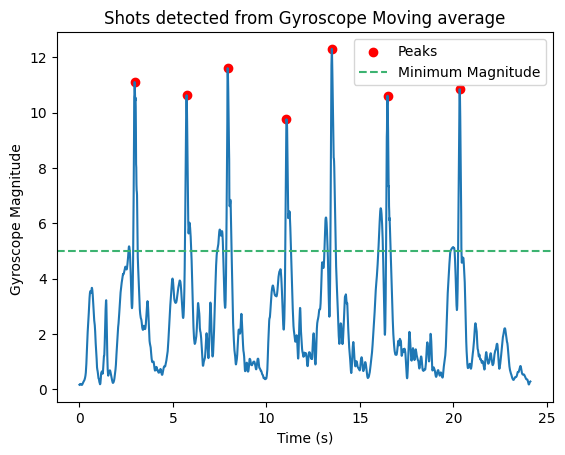

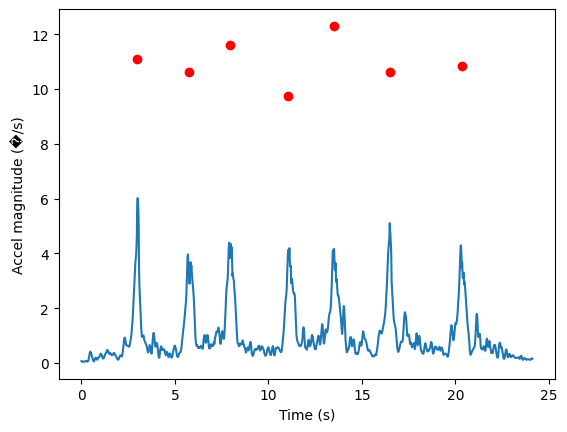

In [13]:
# shot_filenames_list,shots_made= readfilesinfolder(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Watch Sensor/')
# disha_datapath= f'{path}/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Data/'
# disha_forev_filepaths= [f'{disha_datapath}00858_CalInertialAndMag.csv', f'{disha_datapath}00860_CalInertialAndMag.csv']
# disha_backv_filepaths= [f'{disha_datapath}00859_CalInertialAndMag.csv', f'{disha_datapath}00862_CalInertialAndMag.csv']
# disha_serve_filepaths= [f'{disha_datapath}00057_CalInertialAndMag.csv', f'{disha_datapath}00067_CalInertialAndMag.csv', f'{disha_datapath}00070_CalInertialAndMag.csv']

#forehands
AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,Allfpitch, AllfRoll,Allfyaw,Allfname,Allfshot,Allfshots_made = Compile(shot_filenames_list[0],Fore_henry)
faMax, faMin, faMean, faStd, faArea, fgMax, fgMin, fgMean, fgStd, fgArea = MaxMin(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ)
AllfGyro_av, AllfAccel_av, LinSpeeds, thetah_f, thetal_f, magAlow_f, magAhigh_f =feature_template(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ,Allfname,Allfpitch, AllfRoll,Allfyaw,Allfshot,Fore_henry)
# # #backhands
AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ,Allbpitch, AllbRoll,Allbyaw,Allbname,Allbshot,Allbshots_made = Compile(shot_filenames_list[1],Back_henry)
baMax,baMin,baMean,baStd,baArea,bgMax,bgMin,bgMean,bgStd,bgArea = MaxMin(AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ)
AllbGyro_av, AllbAccel_av, LinSpeeds, thetah_b, thetal_b, magAlow_b, magAhigh_b =feature_template(AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ,Allbname,Allbpitch, AllbRoll,Allbyaw,Allbshot,Back_henry)
# # # volley backhands
AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ,Allvbpitch, AllvbRoll,Allvbyaw,Allvbname,Allvbshot,Allvbshots_made = Compile(shot_filenames_list[3],BackV_henry)
vbaMax, vbaMin, vbaMean, vbaStd, vbaArea, vbgMax, vbgMin, vbgMean, vbgStd, vbgArea = MaxMin(AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ)
AllvbGyro_av, AllvbAccel_av, LinSpeedvb, thetah_vb, thetal_vb, magAlow_vb, magAhigh_vb = feature_template(AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ,Allvbname,Allvbpitch, AllvbRoll,Allvbyaw,Allvbshot,BackV_henry)

# # #volleuyfrehands
AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ,Allvfpitch, AllvfRoll,Allvfyaw,Allvfname,Allvfshot,Allvfshots_made = Compile(shot_filenames_list[2],ForeV_henry)
vfaMax, vfaMin, vfaMean, vfaStd, vfaArea, vfgMax, vfgMin, vfgMean, vfgStd, vfgArea = MaxMin(AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ)
AllvfGyro_av, AllvfAccel_av, LinSpeedvf, thetah_vf, thetal_vf, magAlow_vf, magAhigh_vf = feature_template(AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ,Allvfname,Allvfpitch, AllvfRoll,Allvfyaw,Allvfshot,BackV_henry)
# # #serves
AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ,Allspitch, AllsRoll,Allsyaw,Allsname,Allsshot,Allsshots_made = Compile(shot_filenames_list[4],Serve_henry)
saMax, saMin, saMean, saStd, saArea, sgMax, sgMin, sgMean, sgStd, sgArea = MaxMin(AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ)
AllsGyro_av, AllsAccel_av, LinSpeeds, thetah_s, thetal_s, magAlow_s, magAhigh_s =feature_template(AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ,Allsname,Allspitch, AllsRoll,Allsyaw,Allsshot,Serve_henry)


In [45]:

prefix= ['Allf','Allvf','Allb','Allvb','Alls']
PerformanceMetrics = pd.DataFrame(columns=['Player','Shot','Total Racket Speed','Racket Head Speed due to rotation','Angular Velocity','Wrist Velocity'])
for j,i in enumerate(prefix):
    exec(f"performance({i}AccelX, {i}AccelY, {i}AccelZ, {i}GyroX, {i}GyroY, {i}GyroZ,{i}name,shots_type[{j}])")

# PerformanceMetrics.to_csv('PerformanceMetrics4.csv', index= False)

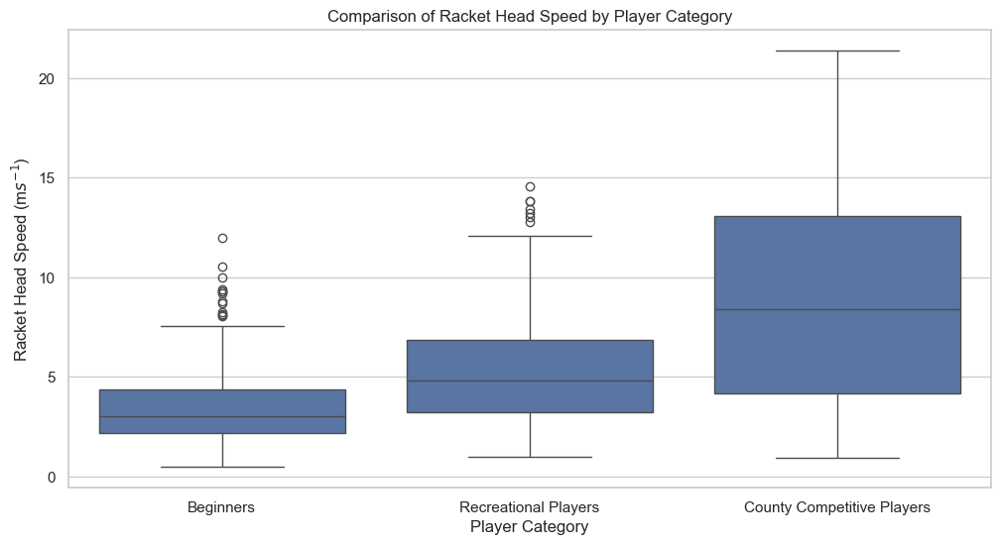

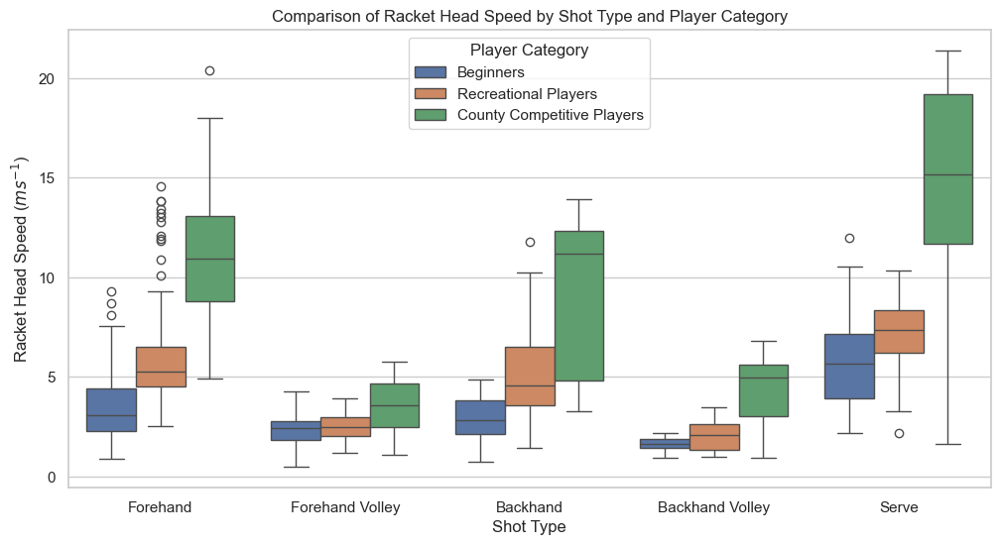

In [256]:

### Step 1: Load and Inspect the CSV File


import pandas as pd

# Load the CSV file
file_path = 'PerformanceMetrics4.csv'
data = pd.read_csv(file_path)

# Display the first few rows of the data
data.head()

### Step 2: Categorize Players

# Define player categories
player_categories = {
    'Beginners': ['Wisdom', 'Amber', 'Ambie','Nnena','Nnnena','Nnenna', 'Kareena', 'Smriti'],
    'Recreational Players': ['Oliver', 'Fran', 'Josh', 'Tom'],
    'County Competitive Players': ['Henry', 'Alex']
}

# Add a new column to the DataFrame for player categories
def categorize_player(player_name):
    for category, players in player_categories.items():
        if player_name in players:
            return category
    return 'Unknown'

data['Category'] = data['Player'].apply(categorize_player)

### Step 3: Generate Visualizations

#### 1. Comparison of Racket Head Speed by Player Category

# Set up the plotting style
# sns.set(style="whitegrid")

# Boxplot for comparison of racket head speed by player category
plt.figure(figsize=(12, 6))
sns.boxplot(x='Category', y='Total Racket Speed', data=data)
plt.xlabel('Player Category')
plt.ylabel('Racket Head Speed (m$s^{-1}$)')
plt.title('Comparison of Racket Head Speed by Player Category')
# plt.xticks(rotation=45)
plt.show()

#### 2. Shot Analysis: Racket Head Speed for Different Types of Shots by Player Category

# Boxplot for shot analysis by player category
plt.figure(figsize=(12, 6))
sns.boxplot(x='Shot', y='Total Racket Speed', hue='Category', data=data)
plt.xlabel('Shot Type')
plt.ylabel('Racket Head Speed ($ms^{-1}$)')
plt.title('Comparison of Racket Head Speed by Shot Type and Player Category')
plt.legend(title='Player Category')
# plt.xticks(rotation=45)
plt.show()



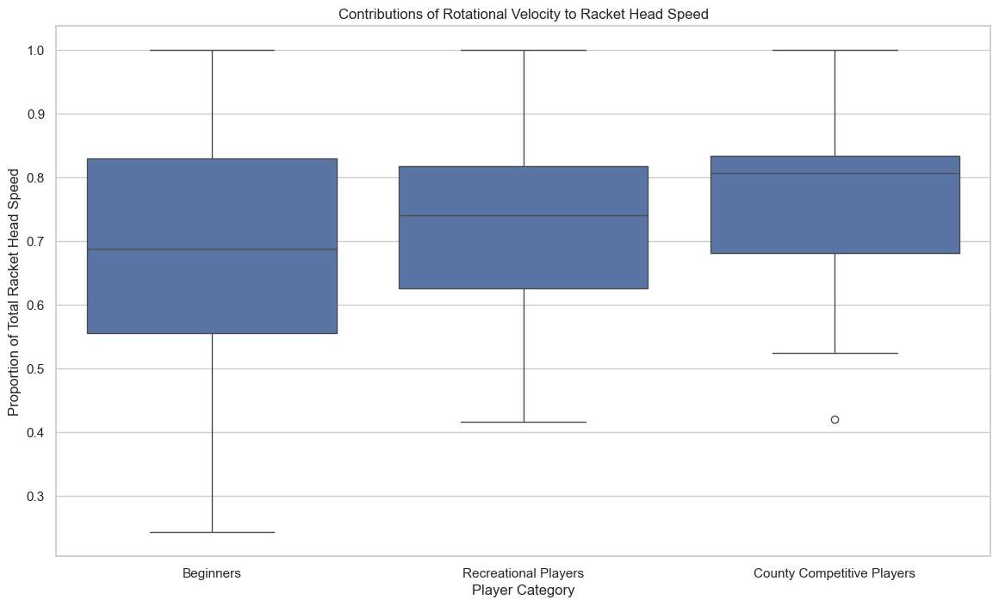

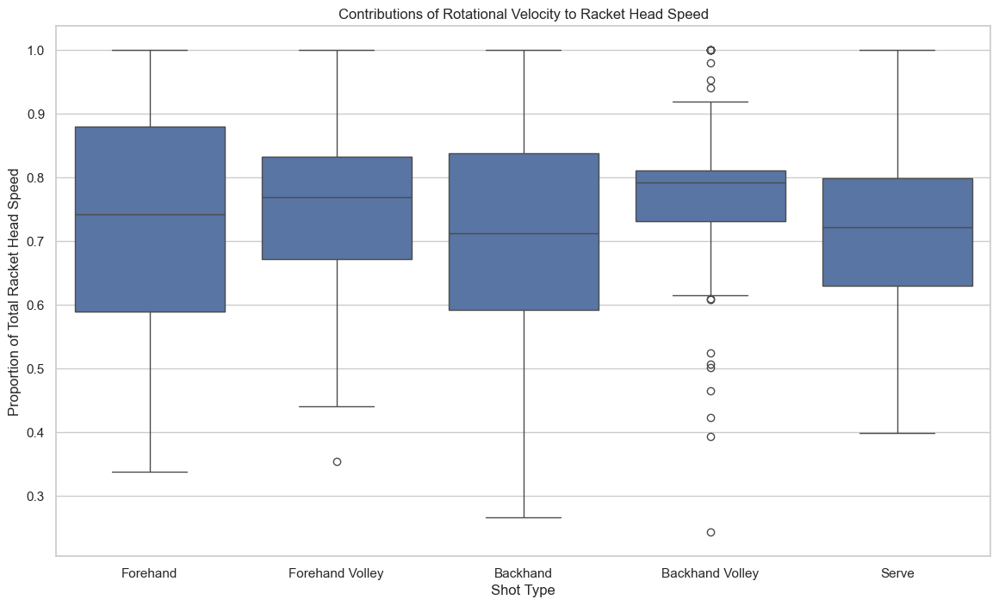

In [263]:
# Calculate the proportions
# Load the CSV file
file_path = 'PerformanceMetrics4.csv'
data = pd.read_csv(file_path)

data['Category'] = data['Player'].apply(categorize_player)
# data['WristVelocityProportion'] = data['Wrist Velocity'] / data['Total Racket Speed']
data['RacketHeadVelocityRotationProportion'] = data['Racket Head Speed due to rotation'] / data['Total Racket Speed']

# Prepare data for visualization
melted_data = data.melt(id_vars=['Player', 'Category', 'Shot', 'Total Racket Speed'], 
                        value_vars=['RacketHeadVelocityRotationProportion'],
                        var_name='VelocityComponent', value_name='Proportion')

# Boxplot for proportion of wrist velocity and racket head velocity due to rotation by player category
plt.figure(figsize=(14, 8))
ax= sns.boxplot(x='Category', y='Proportion', hue='VelocityComponent', data=melted_data,legend=False)
plt.xlabel('Player Category')
plt.ylabel('Proportion of Total Racket Head Speed')
plt.title('Contributions of Rotational Velocity to Racket Head Speed')
# turn off legend
# ax.legend_.remove() 

# plt.xticks(rotation=45)
plt.show()
# Boxplot for proportion of wrist velocity and racket head velocity due to rotation by shot type and player category
plt.figure(figsize=(14, 8))
axe= sns.boxplot(x='Shot', y='Proportion', hue='VelocityComponent', data=melted_data,legend=False)
# axe.legend_.remove() 
plt.xlabel('Shot Type')
plt.ylabel('Proportion of Total Racket Head Speed')
plt.title('Contributions of Rotational Velocity to Racket Head Speed')
# plt.legend(title='Velocity Component')
# plt.xticks(rotation=45)

plt.show()











In [60]:
# putting features of each shot into an array for train test  later on - this is my data set
aMaxAll = np.vstack((faMax, vfaMax, baMax, vbaMax, saMax))
aMinAll = np.vstack((faMin, vfaMin, baMin, vbaMin, saMin))
aMeanAll = np.vstack((faMean, vfaMean, baMean, vbaMean, saMean))
aStdAll = np.vstack((faStd, vfaStd, baStd, vbaStd, saStd))
aAreaAll = np.vstack((faArea, vfaArea, baArea, vbaArea, saArea))
gMinAll = np.vstack((fgMin, vfgMin, bgMin, vbgMin, sgMin))
gMaxAll = np.vstack((fgMax, vfgMax, bgMax, vbgMax, sgMax))
gMeanAll = np.vstack((fgMean, vfgMean, bgMean, vbgMean, sgMean))
gStdAll = np.vstack((fgStd, vfgStd, bgStd, vbgStd, sgStd))
gAreaAll = np.vstack((fgArea, vfgArea, bgArea, vbgArea, sgArea))
# fA = np.hstack((gMinAll, gMaxAll, gMeanAll, gStdAll, gAreaAll))
fA = np.hstack((aMaxAll, aMinAll, aMeanAll, aStdAll, aAreaAll,  gMaxAll,gMinAll, gMeanAll, gStdAll, gAreaAll))
# fQ= np.hstack((aAreaAll,gMaxAll,gMinAll, gMeanAll, gStdAll, gAreaAll))
# 
# Generate table for testing trained model
# And also add a column to show which class/type of stroke it is
t_1 = np.zeros((len(aAreaAll[:,1]),1), dtype=object)   
shots=[]

count= 0
for i in [faMax,vfaMax, baMax,  vbaMax, saMax]:
    shots += [count+len(i[:,1])]
    count+= len(i[:,1])

t_1[0:shots[0]] = 'Forehand'  # forehand  126
t_1[shots[0]:shots[1]] = 'Volley Forehand'  #volley forehand 57 
t_1[shots[1]:shots[2]] = 'Backhand' # backhand 
t_1[shots[2]:shots[3]] = 'Volley Backhand' # volley backhand 58
t_1[shots[3]:shots[4]] = 'Serve'  # serve 66
names= np.hstack((Allfname,Allvfname,Allbname,Allvbname,Allsname))
# #Convert t_1 with hot encoding
data_w_name=np.hstack((fA,t_1))
df= pd.DataFrame(data_w_name, columns= ['a_xmax','a_ymax','a_zmax','a_xmin','a_ymin','a_zmin','a_xmean','a_ymean','a_zmean','a_xstd','a_ystd','a_zstd','a_xarea','a_yarea','a_zarea','g_xmax','g_ymax','g_zmax','g_xmin','g_ymin','g_zmin','g_xmean','g_ymean','g_zmean','g_xstd','g_ystd','g_zstd','g_xarea','g_yarea','g_zarea','shot_type'])
df= pd.get_dummies(df, columns= ['shot_type'])  #one hot encoding

# df= pd.DataFrame(data_w_name, columns= ['Gyro x min','Gyro y min','Gyro z min','gyro_x_max','gyro_y_max','gyro_z_max','gyro_x_mean','gyro_y_mean','gyro_z_mean','gyro_x_std','gyro_y_std','gyro_z_std','gyro_x_area','gyro_y_area','gyro_z_area','shot_type'])
# df_encoded= pd.get_dummies(df, columns= ['shot_type'])  #one hot encoding
# # df.drop('shot_type', axis=1, inplace= True)
# # df= pd.concat([df,df_encoded], axis=1)
# #save as a dataframe with the relevant column names and save as a csv file w the shot type as the last column
# #also split into training and test datasets
# this creates an array of predicted qualities based on coach input
quality= []
for j in range(len(names)):
    if t_1[j] == 'Backhand':
        if names[j]== "Henry" or names[j]== "Alex" or names[j]== "Tom":
            quality+= ["Great"]
        elif names[j]== "Josh"  or names[j]== "Fran":
            quality+= ["Good"]
        elif names[j]== "Smriti" :
            quality+= ["Alright"]
        elif names[j]== "Wisdom" or names[j]== "Amber" or names[j]== "Ambie":
            quality+= ["Subpar"]
        elif names[j]== "Kareena" or names[j]== "Oliver" or names[j]== "Nnena" or names[j]== "Nnnena":
            quality+= ["Alright"]
        else:
            quality+= ["Alright"]
    elif t_1[j] == 'Forehand' or t_1[j] == 'Volley Forehand':
        if names[j]== "Henry" or names[j]== "Alex":
            quality+= ["Great"]
        elif names[j]== "Josh"  or names[j]== "Fran" or names[j]== "Tom":
            quality+= ["Good"]
        elif names[j]== "Smriti" :
            quality+= ["Alright"]
        elif names[j]== "Wisdom" or names[j]== "Amber" or names[j]== "Ambie":
            quality+= ["Subpar"]
        elif names[j]== "Kareena" or names[j]== "Oliver" or names[j]== "Nnena":
            quality+= ["Alright"]
        else:
            quality+= ["Alright"]
    else:
        if names[j]== "Henry" or names[j]== "Alex":
            quality+= ["Great"]
        elif names[j]== "Josh" or names[j]== "Tom" :
            quality+= ["Good"]
        elif names[j]== "Smriti" or names[j]== "Fran":
            quality+= ["Alright"]
        elif names[j]== "Wisdom" or names[j]== "Amber" or names[j]== "Ambie" :
            quality+= ["Subpar"]
        elif names[j]== "Kareena" or names[j]== "Oliver" or names[j]== "Nnena":
            quality+= ["Alright"]
        else:
            quality+= ["Alright"]

# df['Quality']= quality






In [63]:
# t_1= df['Quality']
# df.drop('Quality', axis=1, inplace= True)
X_train, X_test, y_train, y_test = train_test_split(fA, t_1, test_size=0.2)
# pca= joblib.load(f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/MODELS/pca99_5shot.pkl')
# fA_std= pca.transform(fA_std)
#standardize the data
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)
# pca= PCA(n_components=0.99)
# X_train_std_pca= pca.fit_transform(X_train_std)
# X_test_std_pca= pca.transform(X_test_std)
# from imblearn.over_sampling import SMOTE
# smote = SMOTE(random_state=42)
# X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
# X_train_resampled_std = scaler.fit_transform(X_train_resampled)
# X_test_std = scaler.transform(X_test)



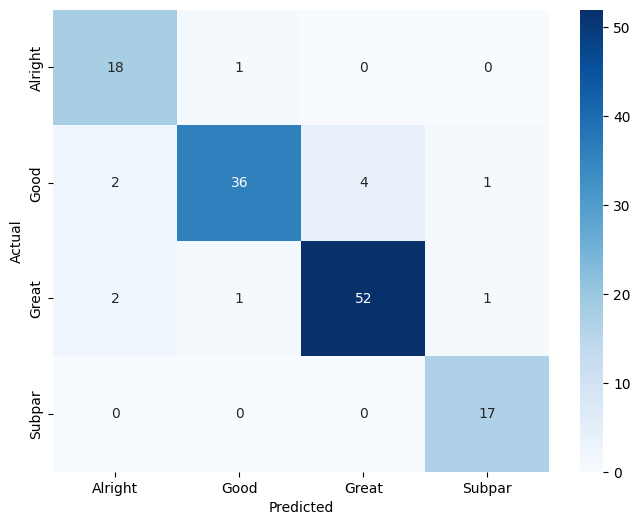

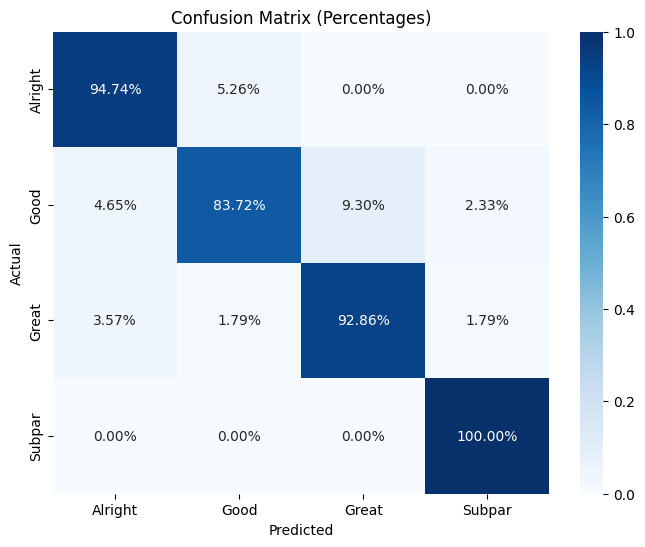

Accuracy is 91.11111111111111 %


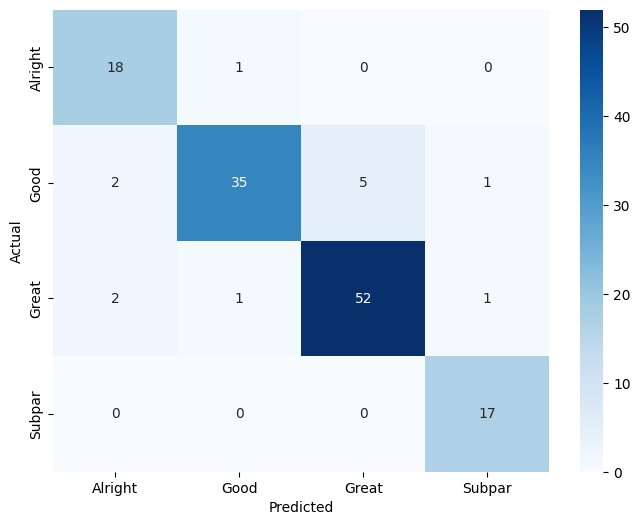

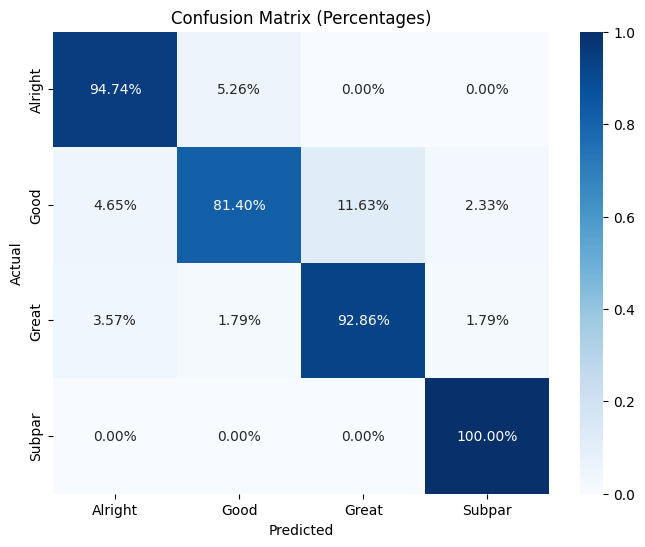

Accuracy is 90.37037037037037 %


In [86]:
# # train svm


svm_qual1 =  SVC(kernel='rbf', C=5, gamma='auto', probability=True, class_weight='balanced')
svm_qual1.fit( X_train_std , y_train)
y_pred= svm_qual1.predict(X_test_std)
labels = svm_qual1.classes_
confusion_and_accuracy(y_test, y_pred, labels,'Wisdom')

svm_nobalance =  SVC(kernel='rbf', C=5, gamma='auto', probability=True)
svm_nobalance.fit(X_train_std , y_train)
y_pred= svm_nobalance.predict(X_test_std)
labels = svm_nobalance.classes_
confusion_and_accuracy(y_test, y_pred, labels,'Wisdom')


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import coremltools as ct
# this script packages the svm and scaler as a pipeline to be imported into xcode for use
# # Define the input feature names
# input_features = ['acceleration_x_max', 'acceleration_y_max', 'acceleration_z_max', 'acceleration_x_min',
#                   'acceleration_y_min', 'acceleration_z_min', 'acceleration_x_mean', 'acceleration_y_mean',
#                   'acceleration_z_mean', 'acceleration_x_std', 'acceleration_y_std', 'acceleration_z_std',
#                   'acceleration_x_area', 'acceleration_y_area', 'acceleration_z_area', 'gyro_x_min', 'gyro_y_min',
#                   'gyro_z_min', 'gyro_x_max', 'gyro_y_max', 'gyro_z_max', 'gyro_x_mean', 'gyro_y_mean',
#                   'gyro_z_mean', 'gyro_x_std', 'gyro_y_std', 'gyro_z_std', 'gyro_x_area', 'gyro_y_area', 'gyro_z_area']
# input_features = ['acceleration_x_mean', 'acceleration_y_mean',
#                   'acceleration_z_mean', 
#                   'acceleration_x_area', 'acceleration_y_area', 'acceleration_z_area', 'gyro_x_min', 'gyro_y_min',
#                   'gyro_z_min', 'gyro_x_max', 'gyro_y_max', 'gyro_z_max', 'gyro_x_mean', 'gyro_y_mean',
#                   'gyro_z_mean', 'gyro_x_area', 'gyro_y_area', 'gyro_z_area']

# Create the scikit-learn pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Standardize features by removing the mean and scaling to unit variance
    ('svm', SVC(kernel='rbf', C=5, gamma='auto'))  # Support Vector Machine classifier
])

# Train the pipeline (assuming you have your training data X_train, y_train)
pipeline.fit(fA_disha, t_disha)

# ,'Backhand','Forehand','Serve','Volley Backhand','Volley Forehand'
coreml_model =  coremltools.converters.sklearn.convert(pipeline, input_features=['acceleration_x_max','acceleration_y_max','acceleration_z_max','acceleration_x_min','acceleration_y_min','acceleration_z_min','acceleration_x_mean','acceleration_y_mean','acceleration_z_mean','acceleration_x_std','acceleration_y_std','acceleration_z_std','acceleration_x_area','acceleration_y_area','acceleration_z_area','gyro_x_max','gyro_y_max','gyro_z_max','gyro_x_min','gyro_y_min','gyro_z_min','gyro_x_mean','gyro_y_mean','gyro_z_mean','gyro_x_std','gyro_y_std','gyro_z_std','gyro_x_area','gyro_y_area','gyro_z_area'], output_feature_names='Shot type')
coreml_model.save('SVM_Disha7Class.mlmodel')

/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [31]:
randf = ensemble.RandomForestClassifier(n_estimators=100, max_depth=20, max_features='auto', min_samples_leaf=1, min_samples_split=2, bootstrap=False)
randf.fit(X_train_disha, y_train_disha)
y_pred_disha = randf.predict(X_test_disha)
labels= ['Forehand','Forehand Volley','Backhand','Backhand Volley ','Serve']
# labels= ['Forehand','Backhand','Serve']
# labels = ['Forehand Topspin', 'Forehand Slice', 'Volley Forehand', 'Backhand Topspin', 'Backhand Slice', 'Volley Backhand', 'Serve']
confusion_and_accuracy(y_test_disha, y_pred_disha,labels,'Wisdom')

# # Now make secondary random forest model to classify each shot into volley slice and topspin
# t_2
# rand2f = ensemble.RandomForestClassifier(n_estimators=100, max_depth=20)


NameError: name 'X_train_disha' is not defined

In [30]:
# This helps to visualise the difference in acceleration and gyroscope magnitudes when comparing players- stark differences for different skilled plaeyrs
# Show a breakdown of the shots made by each player in a datafram
df= pd.DataFrame(columns= ['Shot','Player'])
# Categorise by shot type
df['Shot'] = t_1.flatten()
df['Player'] = names
df['Acceleration Magnitude']= np.sqrt(fA[:,0]**2+fA[:,1]**2+fA[:,2]**2)
df['Gyro Magnitude']= np.sqrt(fA[:,5]**2+fA[:,6]**2+fA[:,7]**2)

In [31]:
# Breakdown of shots made by each player
df.to_csv('Shot Breakdown.csv', index= False)

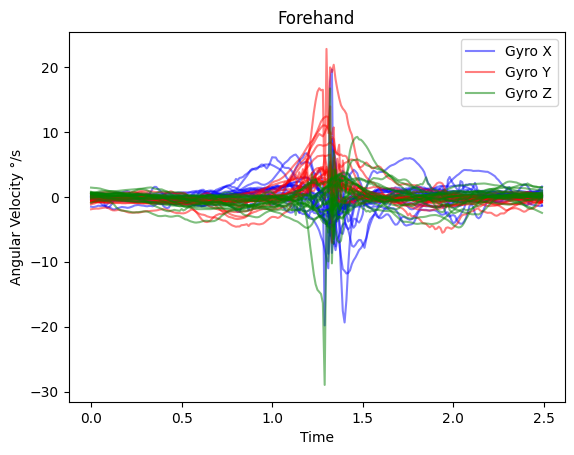

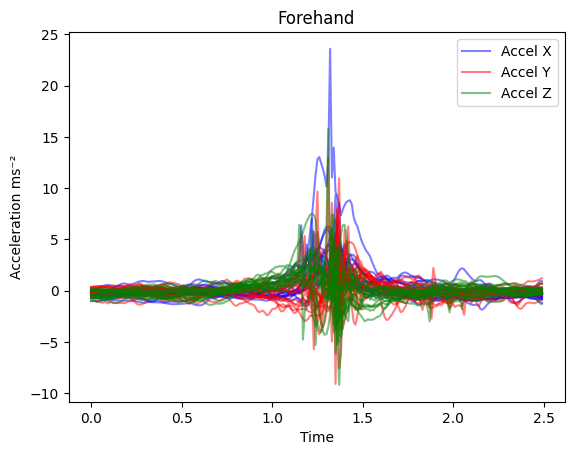

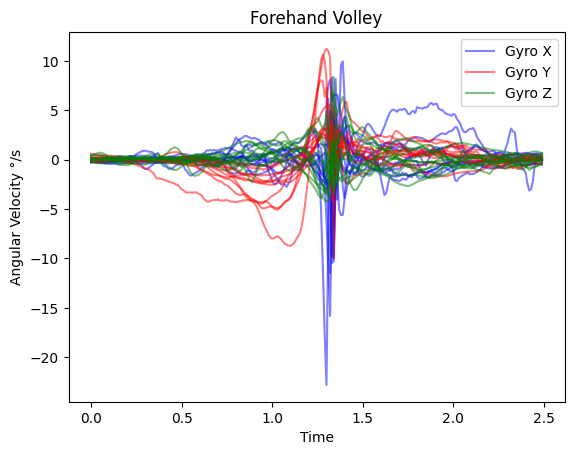

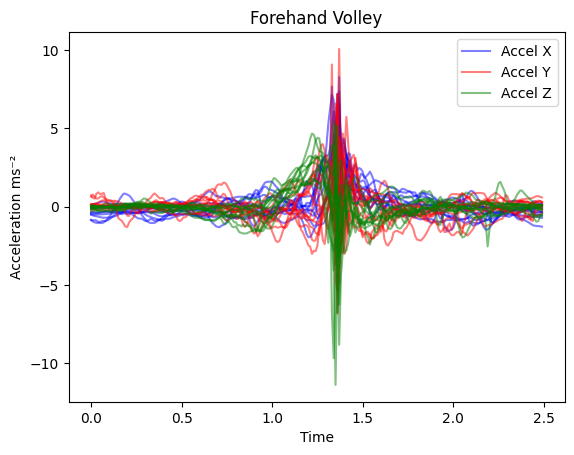

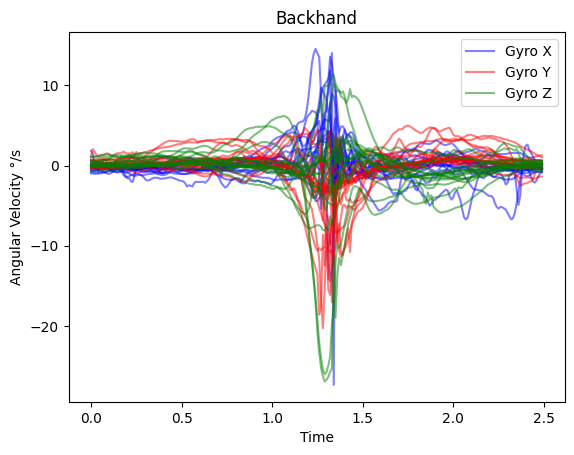

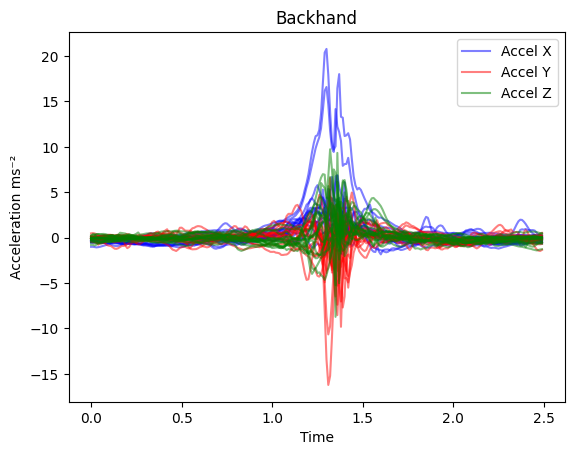

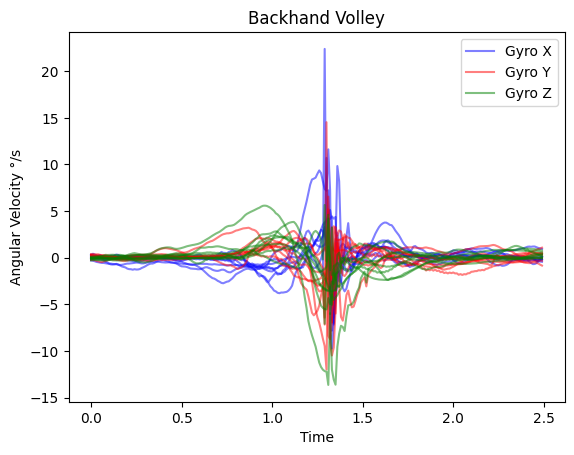

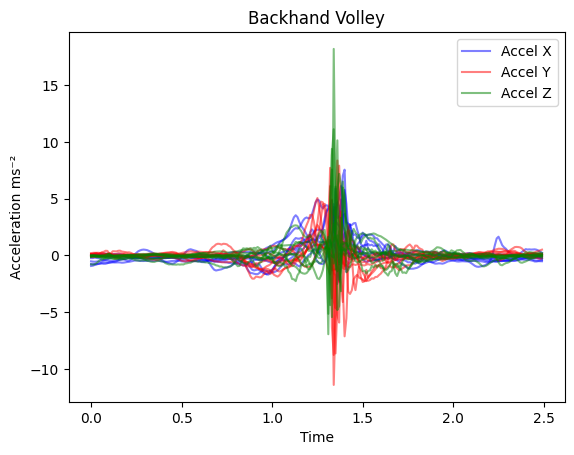

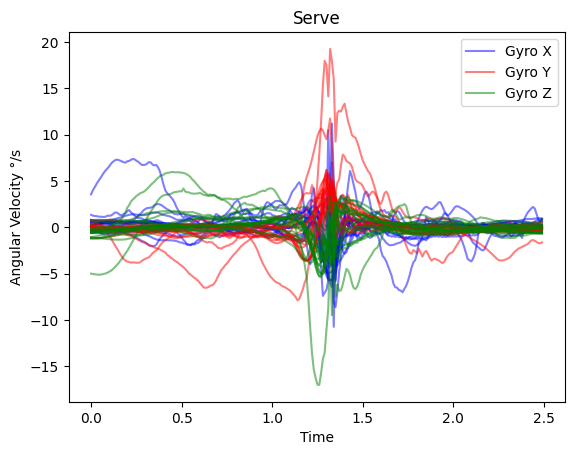

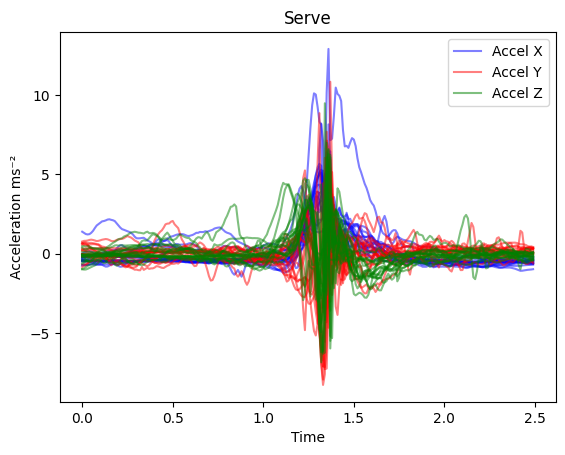

In [21]:
# plot 10 shots - this was for overlaying aligned signals
prefix= ['Allf','Allvf','Allb','Allvb','Alls']
shots_type = ['Forehand','Forehand Volley','Backhand','Backhand Volley','Serve']
# Plot the overlaid signals for each shot type across all players
time= np.arange(0,250,1)/100
labels={'AccelX':'Accel X','AccelY':'Accel Y','AccelZ':'Accel Z','GyroX':'Gyro X','GyroY':'Gyro Y','GyroZ':'Gyro Z'}
for i in range(0,5):
    signal = prefix[i]
    # plt
    # for j in range(0, eval(f"{signal}GyroX.shape[0] ")):
    plt.plot(time,eval(f"{signal}GyroX[:,0::10]"),color= 'blue',label= 'Gyro X',alpha=0.5)
    plt.plot(time,eval(f"{signal}GyroY[:,0::10]"),color= 'red',label= 'Gyro Y',alpha=0.5)
    plt.plot(time,eval(f"{signal}GyroZ[:,0::10]"),color= 'green',label= 'Gyro Z',alpha=0.5)
    plt.title(f'{shots_type[i]}')
    plt.ylabel(f'Angular Velocity {chr(0x00B0)}/s')
    plt.xlabel('Time')
    set_legend()
    plt.show()
    plt.plot(time,eval(f"{signal}AccelX[:,0::10]"),color= 'blue',label= 'Accel X',alpha=0.5)
    plt.plot(time,eval(f"{signal}AccelY[:,0::10]"),color= 'red',label= 'Accel Y',alpha=0.5)
    plt.plot(time,eval(f"{signal}AccelZ[:,0::10]"),color= 'green',label= 'Accel Z',alpha=0.5)
    plt.title(f'{shots_type[i]}')
    plt.ylabel(f'Acceleration ms{chr(0x207B)}{chr(0x00B2)}')
    plt.xlabel('Time')
    set_legend()
    plt.show()


    # plt.legend(['Gyro X','Gyro Y','Gyro Z','Accel X','Accel Y','Accel Z'])
    # plt.legend()
   

    

On the watch:

+X is to horizontally to the side towards the crown
+Y is to horizontally towards the top edge of the watch
+Z upwards vertically from the watch face

below perfpoorms DDTW across signals using compeittive player as a template

In [169]:
from tslearn import metrics as ts_metrics
# Calculate the DTW distance between the serve signals of each player

serve_signal= np.array([ AllsAccelX, AllsAccelY, AllsAccelZ,AllsGyroX, AllsGyroY, AllsGyroZ]).T
forehand_signal= np.array([ AllfAccelX, AllfAccelY, AllfAccelZ,AllfGyroX, AllfGyroY, AllfGyroZ]).T
backhand_signal= np.array([ AllbAccelX, AllbAccelY, AllbAccelZ,AllbGyroX, AllbGyroY, AllbGyroZ]).T
volley_forehand_signal= np.array([ AllvfAccelX, AllvfAccelY, AllvfAccelZ,AllvfGyroX, AllvfGyroY, AllvfGyroZ]).T
volley_backhand_signal= np.array([ AllvbAccelX, AllvbAccelY, AllvbAccelZ,AllvbGyroX, AllvbGyroY, AllvbGyroZ]).T
signals= [forehand_signal,volley_forehand_signal, backhand_signal,  volley_backhand_signal,serve_signal]
distances = ts_metrics.dtw(serve_signal[Allsname == 'Alex'][3], Serve_henry)
print(distances)
shot_prefix= ['Allf','Allvf','Allb','Allvb','Alls']
# Create loop to calculate the ddtw distance  with the ddtw funciton between the signals of each player and the template
# for each shot type
templates= [Fore_henry, ForeV_henry, Back_henry, BackV_henry, Serve_henry]
DDTW_Distance = pd.DataFrame(columns= ['Player','Shot','Distance'])
for i in range(0, len(players)):
    for j in range(0, len(templates)):
        if players[i] in eval(f"{shot_prefix[j]}name"):
            df= pd.DataFrame()
            df['Player']= [players[i]]
            df['Shot']= [shots_type[j]]
            playershots= eval(f"signals[j][{shot_prefix[j]}name == players[i]]")
            for k in range(0, len(playershots)):
                distance= ts_metrics.dtw(playershots[k], templates[j])
                df['Distance']= distance
                DDTW_Distance= pd.concat([DDTW_Distance,df], axis=0)

92.57927026129146


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_34311/813669120.py:27: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  DDTW_Distance= pd.concat([DDTW_Distance,df], axis=0)


In [39]:
# compute for each player for each shot the 0.1 trimmed mean distance, the IQR, the standard deviation and min and max
player_quality= pd.DataFrame(columns= ['Player','Shot','Mean Distance','IQR','Standard Deviation','Min Distance','Max Distance'])
for i in range(0, len(players)):
    for j in range(0, len(shots_type)):
        if players[i] in eval(f"{shot_prefix[j]}name"):
            player_df= DDTW_Distance[(DDTW_Distance['Player'] == players[i]) & (DDTW_Distance['Shot'] == shots_type[j])]
            mean_distance= stats.trim_mean(player_df['Distance'], 0.1)
            iqr= stats.iqr(player_df['Distance'])
            std_dev= np.std(player_df['Distance'])
            min_distance= np.min(player_df['Distance'])
            max_distance= np.max(player_df['Distance'])
            player_quality= pd.concat([player_quality,pd.DataFrame({'Player': [players[i]],'Shot': [shots_type[j]],'Mean Distance': [mean_distance],'IQR': [iqr],'Standard Deviation': [std_dev],'Min Distance': [min_distance],'Max Distance': [max_distance]})], axis=0)

/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_34311/2121248081.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  player_quality= pd.concat([player_quality,pd.DataFrame({'Player': [players[i]],'Shot': [shots_type[j]],'Mean Distance': [mean_distance],'IQR': [iqr],'Standard Deviation': [std_dev],'Min Distance': [min_distance],'Max Distance': [max_distance]})], axis=0)


In [111]:
# this is just formattign dataframe for quality 
"""Serves-
Very good- Henry, Alex
Good- Josh, Tom
Alright- Smriti & Fran
Bad- Amber & Wisdom

Backhand-
Very good- Henry, Tom (footwork is bad)
Good- Josh , Francesca 
Alright- Oliver 
Bad- Wisdom
Forehand
Very good Henry, Tom
Good- Fran Josh
Alright- Smriti
Bad- Amber & Wisdom
"""
# Rename the players based on the assessed quality level
player_quality['Player'][player_quality['Shot'] == 'Serve']= player_quality['Player'][player_quality['Shot'] == 'Serve'].replace({'Henry': 'Very Good', 'Alex': 'Very Good', 'Josh': 'Good', 'Tom': 'Good', 'Smriti': 'Alright', 'Fran': 'Alright', 'Wisdom': 'Bad', 'Amber': 'Bad'})
player_quality['Player'][player_quality['Shot'] == 'Back']= player_quality['Player'][player_quality['Shot'] == 'Back'].replace({'Henry': 'Very Good', 'Tom': 'Very Good', 'Josh': 'Good', 'Fran': 'Good', 'Oliver': 'Alright', 'Wisdom': 'Bad'})
player_quality['Player'][player_quality['Shot'] == 'Fore']= player_quality['Player'][player_quality['Shot'] == 'Fore'].replace({'Henry': 'Very Good', 'Fran': 'Good', 'Oliver': 'Alright', 'Wisdom': 'Bad', 'Amber': 'Bad'})
# Then replace other non assessed names based on avg quality level
player_quality['Player']= player_quality['Player'].replace({'Kareena': 'Alright', 'Alex': 'Very Good', 'Oliver': 'Alright', 'Henry': 'Very Good', 'Josh': 'Good', 'Tom': 'Good', 'Smriti': 'Alright', 'Fran': 'Good', 'Wisdom': 'Bad', 'Amber': 'Bad','Nnena': 'Alright'})

    Player   Shot   Distance      Score
0   Smriti   Fore  91.702720  24.674475
0   Smriti   Fore  93.562902  23.590869
0   Smriti   Fore  86.431806  27.744927
0   Smriti   Fore  91.405738  24.847476
0   Smriti   Fore  95.571732  22.420670
..     ...    ...        ...        ...
0     Alex  Serve  86.228611  37.961306
0     Alex  Serve  90.996961  37.140735
0     Alex  Serve  93.472403  36.714743
0     Alex  Serve  88.885441  37.504100
0     Alex  Serve  90.447631  37.235267

[621 rows x 4 columns]


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_34311/1804523694.py:20: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  player_quality['Player'][player_quality['Shot'] == 'Serve']= player_quality['Player'][player_quality['Shot'] == 

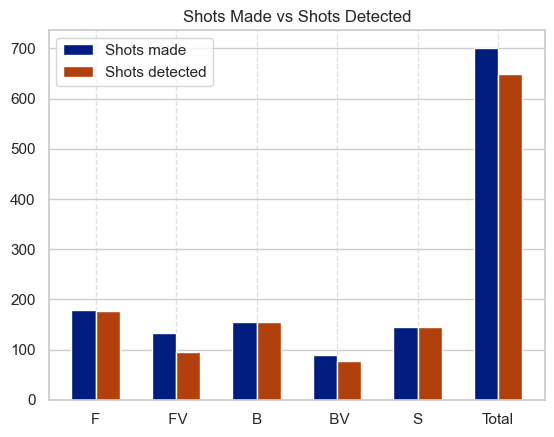

Forehand accuracy: 98.88%
Backhand accuracy: 100.65%
Serve accuracy: 100.0%
Volley Forehand accuracy: 71.43%
Volley Backhand accuracy: 85.56%
Overall accuracy: 92.44%


In [423]:
import seaborn as sns
import numpy as np
sns.set(style="whitegrid")
shots_made_array= np.hstack((np.sum(Allfshots_made),np.sum(Allvfshots_made),np.sum(Allbshots_made),np.sum(Allvbshots_made),np.sum(Allsshots_made),shots_made))
shots_detected= np.hstack((AllfGyroX.shape[1],AllvfGyroX.shape[1],AllbGyroX.shape[1],AllvbGyroX.shape[1],AllsGyroX.shape[1],aAreaAll.shape[0]))
# shots_detected= np.hstack((shots_detected,aAreaAll.shape[0]))
#tp make sure bars dont overlap s
plt.figure()
r=np.arange(6)
x_labels= ['F',' FV','B',' BV','S','Total']

# Define the width of each bar
width = 0.3

# Define the positions of the bars on the x-axis
r = np.arange(len(x_labels))
# Set color palette
sns.set_palette("dark")
# Plot the shots_made_array
plt.bar(r, shots_made_array, width=width, label='Shots made')

# Plot the shots_detected array
plt.bar(r + width, shots_detected, width=width, label='Shots detected')

# Set the x-axis labels
plt.xticks(r + width/2, x_labels,)

# Add a title and legend
plt.title('Shots Made vs Shots Detected')
plt.legend()
# Show small gird
plt.grid(axis='x', linestyle='--', alpha=0.6)
# Show fine grid
plt.minorticks_on()
# Show the plot
plt.show()
# plt.bar(5+width,aAreaAll.shape[0],width=width)
# plt.xticks(np.hstack((r,6))+width/2,shots_type+['Total'])
# plt.title(f'Detection accuracy {np.round((aAreaAll.shape[0]/shots_made)*100,2)}%')
# plt.legend()
# plt.show()

#Save the data as a whole as a csv file as well as seperately in testing and training
# df = pd.DataFrame(fA)
# df.to_csv('my data/All_featuresg.csv', index=False)
# df = pd.DataFrame(t_1)
# df.to_csv('my data/All_features_labels.csv', index=False)
# print percentage accuracies of each
print(f'Forehand accuracy: {np.round((faArea.shape[0]/np.sum(Allfshots_made))*100,2)}%')
print(f'Backhand accuracy: {np.round((baArea.shape[0]/np.sum(Allbshots_made))*100,2)}%')
print(f'Serve accuracy: {np.round((saArea.shape[0]/np.sum(Allsshots_made))*100,2)}%')
print(f'Volley Forehand accuracy: {np.round((vfaArea.shape[0]/np.sum(Allvfshots_made))*100,2)}%')
print(f'Volley Backhand accuracy: {np.round((vbaArea.shape[0]/np.sum(Allvbshots_made))*100,2)}%')
print(f'Overall accuracy: {np.round(((aAreaAll.shape[0]-1)/shots_made)*100,2)}%')

In [54]:
import random
# FILEPATH: /c:/Users/wwo20/OneDrive - Imperial College London/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Feature_select_all_code.ipynb
# Below function saves data for training with coreml and otherwise
def save_shots_to_csv(shot_path): #, include_pitch_roll_yaw, train_split=0.8):
    shot_types = ['Forehand', 'Volley Forehand', 'Backhand', 'Volley Backhand', 'Serve']
    data_prefixes = ['Allf', 'Allvf', 'Allb', 'Allvb', 'Alls']
    # for quality in ['Great', 'Good', 'Alright', 'Subpar']:
    #     os.makedirs(f'{shot_path}/Quality/{quality}', exist_ok=True)
    # os.makedirs(f'{shot_path}/Classifierquality', exist_ok=True)
    for shot_type, prefix in zip(shot_types, data_prefixes):
        # # Create directories
        os.makedirs(f'{shot_path}/Shots5/{shot_type}', exist_ok=True)
   
        # os.makedirs(f'{shot_path}/{shot_type}', exist_ok=True)

        # Get data arrays 
        accel_x = eval(f'{prefix}AccelX')
        accel_y = eval(f'{prefix}AccelY')
        accel_z = eval(f'{prefix}AccelZ')
        gyrox = eval(f'{prefix}GyroX')
        gyroy = eval(f'{prefix}GyroY')
        gyroz = eval(f'{prefix}GyroZ')
        #standardise the data before saving
        scaler = StandardScaler()
        accel_x = scaler.fit_transform(accel_x)
        accel_y = scaler.fit_transform(accel_y)
        accel_z = scaler.fit_transform(accel_z)
        gyrox = scaler.fit_transform(gyrox)
        gyroy = scaler.fit_transform(gyroy)
        gyroz = scaler.fit_transform(gyroz)
        names = eval(f'{prefix}name')
        # Print rhw scaler mean and std for each feature
        
        # # Create labels

        # shot_labels = np.array(gyrox.shape[1]*[shot_type])
        # # Randomize the shots
        # num_shots = gyrox.shape[1]
        # shot_indices = list(range(num_shots))
        # random.shuffle(shot_indices)
        # quality= []
        # One hot encode manual the shot type
        # shot_type_encode= [0,0,0,0,0]
        # if shot_type == 'Volley Backhand':
        #     shot_type_encode[3]= 1
        # elif shot_type == 'Backhand':
        #     shot_type_encode[2]= 1
        # elif shot_type == 'Volley Forehand':
        #     shot_type_encode[1]= 1
        # elif shot_type == 'Forehand':
        #     shot_type_encode[0]= 1
        # elif shot_type == 'Serve':
        #     shot_type_encode[4]= 1
        for j in range(len(names)):
            if shot_type == 'Backhand':
                if names[j]== "Henry" or names[j]== "Alex" or names[j]== "Tom":
                    quality= ["Great"]
                elif names[j]== "Josh"  or names[j]== "Fran":
                    quality= ["Good"]
                elif names[j]== "Smriti" :
                    quality= ["Alright"]
                elif names[j]== "Wisdom" or names[j]== "Amber" or names[j]== "Ambie":
                    quality= ["Subpar"]
                elif names[j]== "Kareena" or names[j]== "Oliver" or names[j]== "Nnena" or names[j]== "Nnnena":
                    quality= ["Alright"]
                else:
                    quality= ["Alright"]
            elif shot_type== 'Forehand' or shot_type == 'Volley Forehand':
                if names[j]== "Henry" or names[j]== "Alex":
                    quality= ["Great"]
                elif names[j]== "Josh"  or names[j]== "Fran" or names[j]== "Tom":
                    quality= ["Good"]
                elif names[j]== "Smriti" :
                    quality= ["Alright"]
                elif names[j]== "Wisdom" or names[j]== "Amber" or names[j]== "Ambie":
                    quality= ["Subpar"]
                elif names[j]== "Kareena" or names[j]== "Oliver" or names[j]== "Nnena":
                    quality= ["Alright"]
                else:
                    quality= ["Alright"]
            else:
                if names[j]== "Henry" or names[j]== "Alex":
                    quality= ["Great"]
                elif names[j]== "Josh" or names[j]== "Tom" :
                    quality= ["Good"]
                elif names[j]== "Smriti" or names[j]== "Fran":
                    quality= ["Alright"]
                elif names[j]== "Wisdom" or names[j]== "Amber" or names[j]== "Ambie" :
                    quality= ["Subpar"]
                elif names[j]== "Kareena" or names[j]== "Oliver" or names[j]== "Nnena":
                    quality= ["Alright"]
                else:
                    quality= ["Alright"]
            data = {
                'acceleration_x': accel_x[:, j],
                'acceleration_y': accel_y[:, j],
                'acceleration_z': accel_z[:, j],
                'gyrox': gyrox[:, j],
                'gyroy': gyroy[:, j],
                'gyroz': gyroz[:, j]
            }
            df = pd.DataFrame(data)
            # if i < num_shots * train_split:
            df.to_csv(f'{shot_path}/Shots5/{shot_type}/{names[j]}_{j}.csv', index=False, header=True)
           
            
qualitypath= '/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/COREML'
# dishapath = 'my data/All_shots_w_disha'
# rollpitchyawpath = 'my data/All_shots_w_roll_pitch_yaw'
# accelgyropath = 'my data/All_shots_standardised_w_disha'

save_shots_to_csv(qualitypath)

Forehand mean: [0.70800219 0.7170225  0.62272309 0.61721807 0.58796336 0.72178519
 0.67985859 0.70645967 0.57371799 1.01082875 0.69587833 0.90215225
 0.66475474 0.78211712 0.92443591 0.62286064 0.7179722  0.90308118
 0.99656234 0.95544657 0.24779975 0.2889193  0.24168869 0.22888407
 0.19819716 1.80131087 1.7075608  1.56653666 1.46427712 1.81280668
 1.6097832  1.44537268 1.67504654 1.41793736 1.58156023 0.23457514
 0.21722755 0.22697157 0.26498968 0.25329245 0.20467549 0.2163415
 0.17636572 0.20351991 0.13889498 0.23365804 0.29665762 0.16741867
 0.14690391 0.15717397 0.12313468 0.2303999  0.21950578 0.23592974
 0.26950102 0.75580373 0.63967754 0.68177501 0.66179837 0.78451452
 0.81965728 0.74598844 0.62676023 0.63827818 0.62445105 0.45673256
 0.57480834 0.62251831 0.70168632 0.6444913  0.65919322 0.62875404
 0.67875561 0.60809728 0.69214475 0.45314725 0.35657131 0.42874802
 0.29485798 0.2772115  1.11088307 0.88123733 0.81933994 0.69453782
 0.863514   0.93338428 0.74571653 0.78099311 0.8

/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_41482/3119281043.py:2: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  randnew_apple.fit(X_train, y_train)


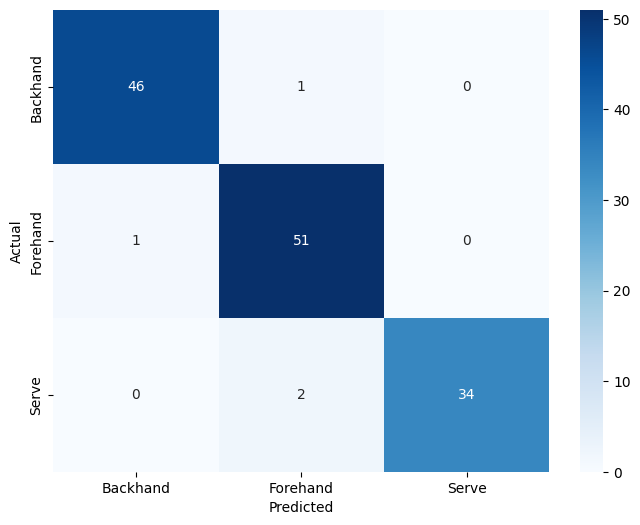

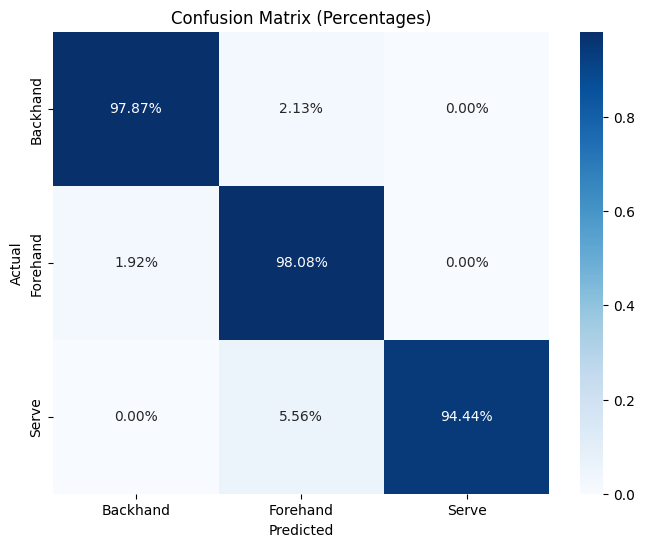

Accuracy is 97.03703703703704 %


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_41482/3119281043.py:8: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  rand_balanced.fit(X_train, y_train)


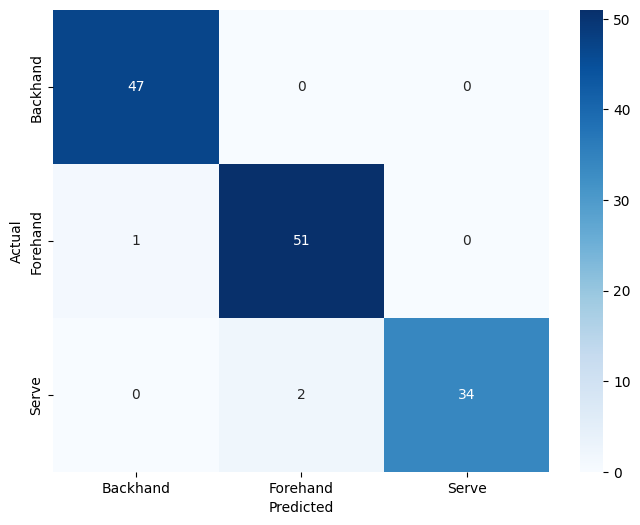

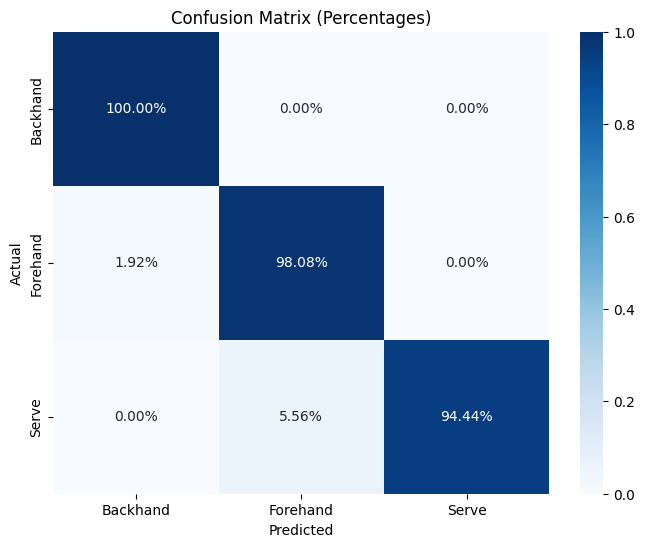

Accuracy is 97.77777777777777 %


In [8]:
randnew_apple= ensemble.RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42)
randnew_apple.fit(X_train, y_train)
y_pred= randnew_apple.predict(X_test)
labels = randnew_apple.classes_
confusion_and_accuracy(y_test, y_pred, labels,'wisdom')

rand_balanced= ensemble.RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, class_weight='balanced')
rand_balanced.fit(X_train, y_train)
y_pred= rand_balanced.predict(X_test)
labels = rand_balanced.classes_
confusion_and_accuracy(y_test, y_pred, labels,'wisdom')


([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29],
 [Text(0, 0, '$\\mathrm{a_x max}$'),
  Text(1, 0, '$\\mathrm{a_y max}$'),
  Text(2, 0, '$\\mathrm{a_z max}$'),
  Text(3, 0, '$\\mathrm{a_x min}$'),
  Text(4, 0, '$\\mathrm{a_y min}$'),
  Text(5, 0, '$\\mathrm{a_z min}$'),
  Text(6, 0, '$\\mathrm{a_x mean}$'),
  Text(7, 0, '$\\mathrm{a_y mean}$'),
  Text(8, 0, '$\\mathrm{a_z mean}$'),
  Text(9, 0, '$\\mathrm{a_x std}$'),
  Text(10, 0, '$\\mathrm{a_y std}$'),
  Text(11, 0, '$\\mathrm{a_z std}$'),
  Text(12, 0, '$\\mathrm{a_x area}$'),
  Text(13, 0, '$\\mathrm{a_y area}$'),
  Text(14, 0, '$\\mathrm{a_z area}$'),
  Text(15, 0, '$\\mathrm{g_x max}$'),
  Text(16, 0, '$\\mathrm{g_y max}$'),
  Text(17, 0, '$\\mathrm{g_z max}$'),
  Text(18, 0, '$\\mathrm{g_x min}$'),
  Text(19, 0, '$\\mathrm{g_y min}$'),
  Text(20, 0, '$\\mathrm{g_z min}$'),
  Text(21, 0, '$\\mathrm{g_x mean}$

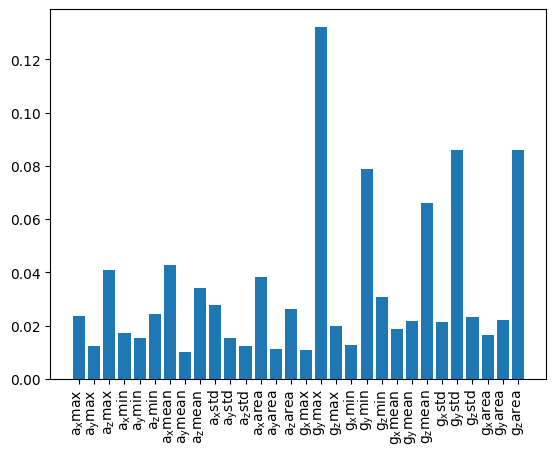

In [40]:
# See the contribution of each feature to the model
importances = randnew_apple.feature_importances_
# Visualize the importance of each feature
plt.figure()
features= ['acceleration_x_max','acceleration_y_max','acceleration_z_max','acceleration_x_min','acceleration_y_min','acceleration_z_min','acceleration_x_mean','acceleration_y_mean','acceleration_z_mean','acceleration_x_std','acceleration_y_std','acceleration_z_std','acceleration_x_area','acceleration_y_area','acceleration_z_area','gyro_x_max','gyro_y_max','gyro_z_max','gyro_x_min','gyro_y_min','gyro_z_min','gyro_x_mean','gyro_y_mean','gyro_z_mean','gyro_x_std','gyro_y_std','gyro_z_std','gyro_x_area','gyro_y_area','gyro_z_area']
features = [r'$\mathrm{a_x max}$', r'$\mathrm{a_y max}$', r'$\mathrm{a_z max}$', r'$\mathrm{a_x min}$', r'$\mathrm{a_y min}$', r'$\mathrm{a_z min}$', r'$\mathrm{a_x mean}$', r'$\mathrm{a_y mean}$', r'$\mathrm{a_z mean}$', r'$\mathrm{a_x std}$', r'$\mathrm{a_y std}$', r'$\mathrm{a_z std}$', r'$\mathrm{a_x area}$', r'$\mathrm{a_y area}$', r'$\mathrm{a_z area}$', r'$\mathrm{g_x max}$', r'$\mathrm{g_y max}$', r'$\mathrm{g_z max}$', r'$\mathrm{g_x min}$', r'$\mathrm{g_y min}$', r'$\mathrm{g_z min}$', r'$\mathrm{g_x mean}$', r'$\mathrm{g_y mean}$', r'$\mathrm{g_z mean}$', r'$\mathrm{g_x std}$', r'$\mathrm{g_y std}$', r'$\mathrm{g_z std}$', r'$\mathrm{g_x area}$', r'$\mathrm{g_y area}$', r'$\mathrm{g_z area}$']
plt.bar(features, importances)
plt.xticks(rotation=90)

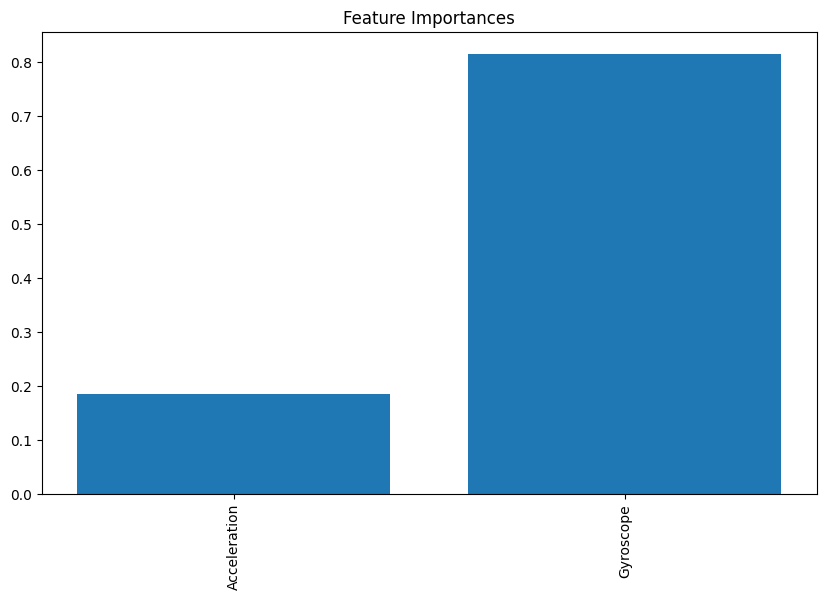

In [163]:
# turn x_Train into a dataframe
input_features= ['acceleration_x_max', 'acceleration_y_max', 'acceleration_z_max', 'acceleration_x_min',
                  'acceleration_y_min', 'acceleration_z_min', 'acceleration_x_mean', 'acceleration_y_mean',
                  'acceleration_z_mean', 'acceleration_x_std', 'acceleration_y_std', 'acceleration_z_std',
                  'acceleration_x_area', 'acceleration_y_area', 'acceleration_z_area', 'gyro_x_min', 'gyro_y_min',
                  'gyro_z_min', 'gyro_x_max', 'gyro_y_max', 'gyro_z_max', 'gyro_x_mean', 'gyro_y_mean',
                  'gyro_z_mean', 'gyro_x_std', 'gyro_y_std', 'gyro_z_std', 'gyro_x_area', 'gyro_y_area', 'gyro_z_area','Fore','Back','Serve','ForeV','BackV']

X_train = pd.DataFrame(X_train, columns= input_features)
# Bar chart of feature importances
plt.figure(figsize=(10, 6))
importances = rand2_apple.feature_importances_
features = X_train.columns
indices = np.argsort(importances)[::-1]

# Show only two bars for acceleration and gyroscope
plt.bar(['Acceleration', 'Gyroscope'], [importances[indices[:3]].sum(), importances[indices[3:]].sum()])
plt.xticks(rotation=90)
plt.title('Feature Importances')
plt.show()

In [164]:
print('Converting to CoreML')
input_features= ['acceleration_x_max', 'acceleration_y_max', 'acceleration_z_max', 'acceleration_x_min',
                  'acceleration_y_min', 'acceleration_z_min', 'acceleration_x_mean', 'acceleration_y_mean',
                  'acceleration_z_mean', 'acceleration_x_std', 'acceleration_y_std', 'acceleration_z_std',
                  'acceleration_x_area', 'acceleration_y_area', 'acceleration_z_area', 'gyro_x_min', 'gyro_y_min',
                  'gyro_z_min', 'gyro_x_max', 'gyro_y_max', 'gyro_z_max', 'gyro_x_mean', 'gyro_y_mean',
                  'gyro_z_mean', 'gyro_x_std', 'gyro_y_std', 'gyro_z_std', 'gyro_x_area', 'gyro_y_area', 'gyro_z_area','Fore','Back','Serve','ForeV','BackV']
coreml_model= coremltools.converters.sklearn.convert(rand2_apple, input_features=input_features, output_feature_names='Quality')
coreml_model.save('Randf_allshots_quality.mlmodel')

Converting to CoreML


/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/utils/deprecation.py:103: FutureWarning: Attribute `n_features_` was deprecated in version 1.0 and will be removed in 1.2. Use `n_features_in_` instead.
  warnings.warn(msg, category=FutureWarning)


(256, 26)
(256, 22)
(256, 28)
(256, 30)
(256, 35)
(256, 23)
(256, 35)
(256, 33)
(256, 22)
(256, 74)
(256, 52)
(256, 63)
(256, 21)
(256, 25)
(256, 26)
(256, 28)
(256, 11)
(256, 23)
(256, 16)


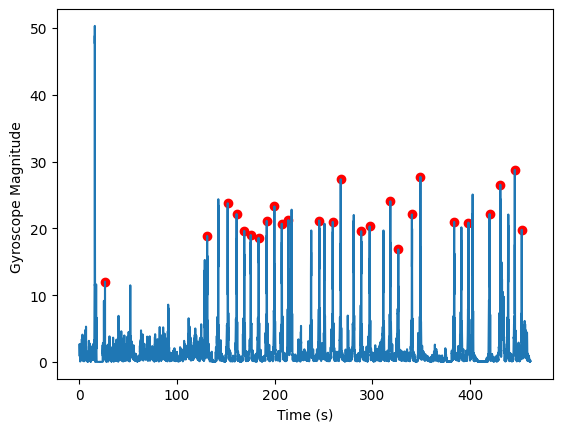

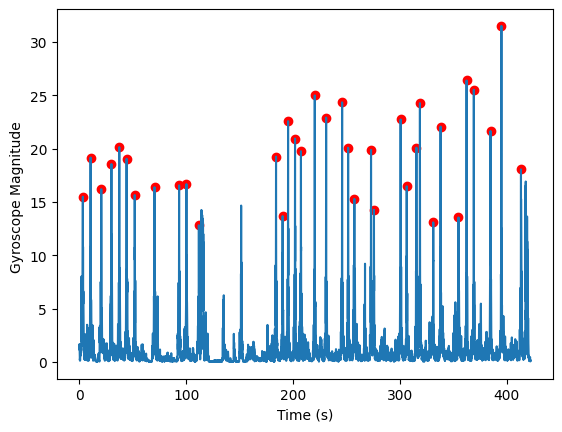

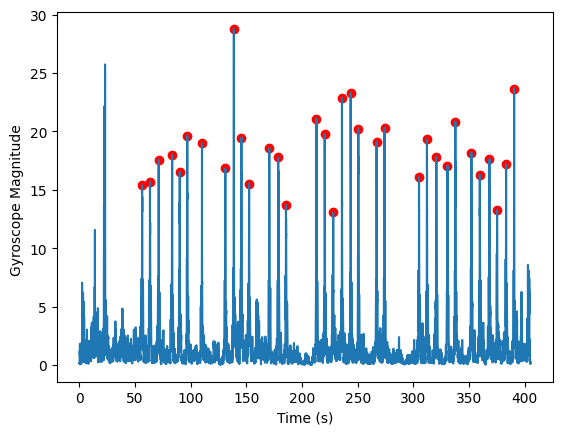

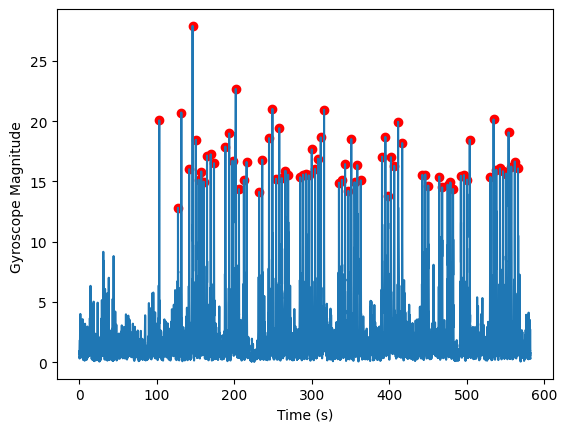

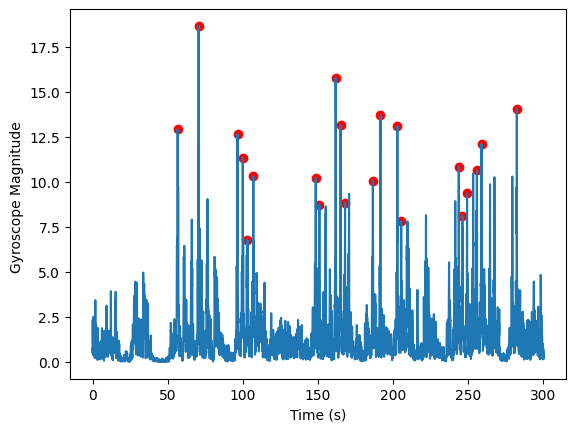

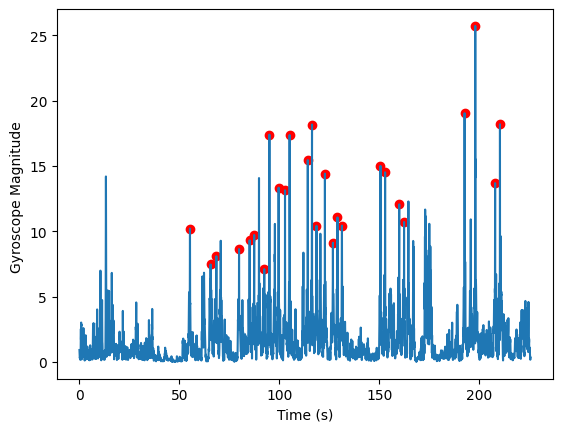

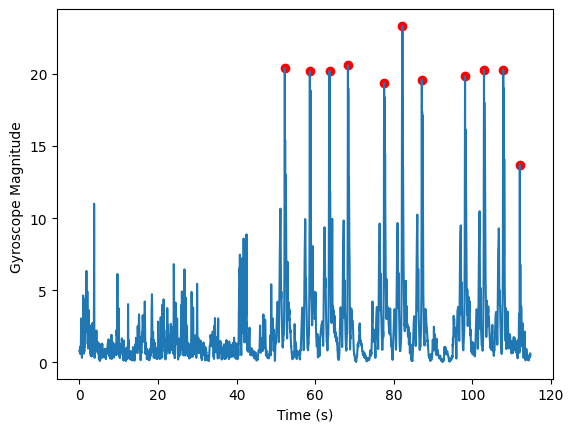

In [47]:
# Disha's datset is being used here with similar detection and segmenttion fucntions being operformed 
# datapath= '/Users/wisdomokoro/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Data/'
datapath= f'{path}uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/Data/'
# Forehand All (126 shots)
filenames = [f'{datapath}00049_CalInertialAndMag.csv', f'{datapath}00060_CalInertialAndMag.csv', f'{datapath}00065_CalInertialAndMag.csv', f'{datapath}00068_CalInertialAndMag.csv']
AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ = Compile_disha(filenames)
# fore_template= cross_corr(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ)
faMax, faMin, faMean, faStd, faArea, fgMax, fgMin, fgMean, fgStd, fgArea = MaxMin(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ)
# AllfGyro_av, AllfAccel_av, LinSpeedf, thetah_f, thetal_f, magAlow_f, magAhigh_f = template(AllfGyroX, AllfGyroY, AllfGyroZ, AllfAccelX, AllfAccelY, AllfAccelZ)

#%%
# Backhand Topspin (139 shots) Disha, Disha, Katarina, Thomas
filenames = [ f'{datapath}00050_CalInertialAndMag.csv', f'{datapath}00066_CalInertialAndMag.csv', f'{datapath}00069_CalInertialAndMag.csv']
AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ = Compile_disha(filenames)
# back_template =cross_corr(AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ)
baMax, baMin, baMean, baStd, baArea, bgMax, bgMin, bgMean, bgStd, bgArea = MaxMin(AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ)
# AllbGyro_av, AllbAccel_av, LinSpeedb, thetah_b, thetal_b, magAlow_b, magAhigh_b = template(AllbGyroX, AllbGyroY, AllbGyroZ, AllbAccelX, AllbAccelY, AllbAccelZ)
#%%#
#Backhand Slice (58 shots) Disha, Disha, Katarina, Thomas
filenames = [ f'{datapath}00856_CalInertialAndMag.csv', f'{datapath}00857_CalInertialAndMag.csv']
AllbsGyroX, AllbsGyroY, AllbsGyroZ, AllbsAccelX, AllbsAccelY, AllbsAccelZ = Compile_disha(filenames)
# Display_Signal(AllbsGyroX, AllbsGyroY, AllbsGyroZ, AllbsAccelX, AllbsAccelY, AllbsAccelZ,128,'Disha Backhand Slice') 
# AllbsGyroX, AllbsGyroY, AllbsGyroZ, AllbsAccelX, AllbsAccelY, AllbsAccelZ = cross_corr(AllbsGyroX, AllbsGyroY, AllbsGyroZ, AllbsAccelX, AllbsAccelY, AllbsAccelZ,128)  
bsaMax, bsaMin, bsaMean, bsaStd, bsaArea, bsgMax, bsgMin, bsgMean, bsgStd, bsgArea = MaxMin(AllbsGyroX, AllbsGyroY, AllbsGyroZ, AllbsAccelX, AllbsAccelY, AllbsAccelZ)
# AllbsGyro_av, AllbsAccel_av, LinSpeedbs, thetah_bs, thetal_bs, magAlow_bs, magAhigh_bs = template(AllbsGyroX, AllbsGyroY, AllbsGyroZ, AllbsAccelX, AllbsAccelY, AllbsAccelZ)
#%%
# Forehand Slice (274 shots) Disha, Hannah, Katarina, thomas
filenames=[f'{datapath}00992_CalInertialAndMag.csv',f'{datapath}00991_CalInertialAndMag.csv',f'{datapath}00994_CalInertialAndMag.csv']
[AllfsGyroX,AllfsGyroY,AllfsGyroZ,AllfsAccelX,AllfsAccelY,AllfsAccelZ]=Compile_disha(filenames)
# Display_Signal(AllfsGyroX,AllfsGyroY,AllfsGyroZ,AllfsAccelX,AllfsAccelY,AllfsAccelZ,128,'Disha Forehand Slice')
# AllfsGyroX, AllfsGyroY, AllfsGyroZ, AllfsAccelX, AllfsAccelY, AllfsAccelZ = cross_corr(AllfsGyroX, AllfsGyroY, AllfsGyroZ, AllfsAccelX, AllfsAccelY, AllfsAccelZ,128)
[fsaMax,fsaMin,fsaMean,fsaStd,fsaArea,fsgMax,fsgMin,fsgMean,fsgStd,fsgArea]= MaxMin(AllfsGyroX,AllfsGyroY,AllfsGyroZ,AllfsAccelX,AllfsAccelY,AllfsAccelZ)
# [AllfsGyro_av, AllfsAccel_av, LinSpeedfs,thetah_fs,thetal_fs,magAlow_fs,magAhigh_fs] = template(AllfsGyroX,AllfsGyroY,AllfsGyroZ,AllfsAccelX,AllfsAccelY,AllfsAccelZ)

# Volley Backhand (58 shots)
filenames = [f'{datapath}00859_CalInertialAndMag.csv', f'{datapath}00862_CalInertialAndMag.csv']
AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ = Compile_disha(filenames)
# volleyback_template = cross_corr(AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ)
vbaMax, vbaMin, vbaMean, vbaStd, vbaArea, vbgMax, vbgMin, vbgMean, vbgStd, vbgArea = MaxMin(AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ)
# Display_Signal(AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ,128,'Disha Volley BH')
# AllvbGyro_av, AllvbAccel_av, LinSpeedvb, thetah_vb, thetal_vb, magAlow_vb, magAhigh_vb = template(AllvbGyroX, AllvbGyroY, AllvbGyroZ, AllvbAccelX, AllvbAccelY, AllvbAccelZ)
# Volley Forehand (57 shots)
filenames = [f'{datapath}00858_CalInertialAndMag.csv', f'{datapath}00860_CalInertialAndMag.csv']
AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ = Compile_disha(filenames)
# Display_Signal(AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ,128,'Disha Volley FH')
# volley_fore_template = cross_corr(AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ)
vfaMax, vfaMin, vfaMean, vfaStd, vfaArea, vfgMax, vfgMin, vfgMean, vfgStd, vfgArea = MaxMin(AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ)
# AllvfGyro_av, AllvfAccel_av, LinSpeedvf, thetah_vf, thetal_vf, magAlow_vf, magAhigh_vf = template(AllvfGyroX, AllvfGyroY, AllvfGyroZ, AllvfAccelX, AllvfAccelY, AllvfAccelZ)
# Serve All (66 shots)
filenames = [f'{datapath}00057_CalInertialAndMag.csv', f'{datapath}00067_CalInertialAndMag.csv', f'{datapath}00070_CalInertialAndMag.csv']
AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ = Compile_disha(filenames)
# serve_template= cross_corr(AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ)
saMax, saMin, saMean, saStd, saArea, sgMax, sgMin, sgMean, sgStd, sgArea = MaxMin(AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ)
# AllsGyro_av, AllsAccel_av, LinSpeeds, thetah_s, thetal_s, magAlow_s, magAhigh_s = template(AllsGyroX, AllsGyroY, AllsGyroZ, AllsAccelX, AllsAccelY, AllsAccelZ)

# Assuming that faMax, baMax, etc. are defined and are NumPy arrays
# Assuming that faMax, baMax, etc. are defined and are NumPy arrays
# aMaxAll = np.vstack((faMax[:45], baMax[:45], fsaMax[:45], bsaMax[:45], vfaMax[:45], vbaMax[:45], saMax[:45]))
# aMinAll = np.vstack((faMin[:45], baMin[:45], fsaMin[:45], bsaMin[:45], vfaMin[:45], vbaMin[:45], saMin[:45]))
# aMeanAll = np.vstack((faMean[:45], baMean[:45], fsaMean[:45], bsaMean[:45], vfaMean[:45], vbaMean[:45], saMean[:45]))
# aStdAll = np.vstack((faStd[:45], baStd[:45], fsaStd[:45], bsaStd[:45], vfaStd[:45], vbaStd[:45], saStd[:45]))
# aAreaAll = np.vstack((faArea[:45], baArea[:45], fsaArea[:45], bsaArea[:45], vfaArea[:45], vbaArea[:45], saArea[:45]))
# gMinAll = np.vstack((fgMin[:45], bgMin[:45], fsgMin[:45], bsgMin[:45], vfgMin[:45], vbgMin[:45], sgMin[:45]))
# gMaxAll = np.vstack((fgMax[:45], bgMax[:45], fsgMax[:45], bsgMax[:45], vfgMax[:45], vbgMax[:45], sgMax[:45]))
# gMeanAll = np.vstack((fgMean[:45], bgMean[:45], fsgMean[:45], bsgMean[:45], vfgMean[:45], vbgMean[:45], sgMean[:45]))
# gStdAll = np.vstack((fgStd[:45], bgStd[:45], fsgStd[:45], bsgStd[:45], vfgStd[:45], vbgStd[:45], sgStd[:45]))
# gAreaAll = np.vstack((fgArea[:45], bgArea[:45], fsgArea[:45], bsgArea[:45], vfgArea[:45], vbgArea[:45], sgArea[:45]))




In [51]:
# Compliling features for trainign and testing from Disha's dataset
aMaxAll_disha = np.vstack((faMax, fsaMax, vfaMax, baMax, bsaMax, vbaMax, saMax))
aMinAll_disha = np.vstack((faMin, fsaMin, vfaMin, baMin, bsaMin, vbaMin, saMin))
aMeanAll_disha = np.vstack((faMean, fsaMean, vfaMean, baMean, bsaMean, vbaMean, saMean))
aStdAll_disha = np.vstack((faStd, fsaStd, vfaStd, baStd, bsaStd, vbaStd, saStd))
aAreaAll_disha = np.vstack((faArea, fsaArea, vfaArea, baArea, bsaArea, vbaArea, saArea))
gMinAll_disha = np.vstack((fgMin, fsgMin, vfgMin, bgMin, bsgMin, vbgMin, sgMin))
gMaxAll_disha = np.vstack((fgMax, fsgMax, vfgMax, bgMax, bsgMax, vbgMax, sgMax))
gMeanAll_disha = np.vstack((fgMean, fsgMean, vfgMean, bgMean, bsgMean, vbgMean, sgMean))
gStdAll_disha = np.vstack((fgStd, fsgStd, vfgStd, bgStd, bsgStd, vbgStd, sgStd))
gAreaAll_disha = np.vstack((fgArea, fsgArea, vfgArea, bgArea, bsgArea, vbgArea, sgArea))
fA_disha= np.hstack((aMaxAll_disha, aMinAll_disha, aMeanAll_disha, aStdAll_disha, aAreaAll_disha, gMaxAll_disha, gMinAll_disha, gMeanAll_disha, gStdAll_disha, gAreaAll_disha))

# Generate table for testing trained model
# And also add a column to show which class/type of stroke it is
t_disha = np.zeros((len(aAreaAll_disha[:,1]), 1),dtype=object)
shots=[]
count= 0
for i in [faMax, fsaMax, vfaMax, baMax, bsaMax, vbaMax, saMax]:
    shots += [count+len(i[:,1])]
    count+= len(i[:,1])
t_disha[0:shots[0]] = "Forehand"
t_disha[shots[0]:shots[1]] = "Slice Forehand"
t_disha[shots[1]:shots[2]] = "Volley Forehand"
t_disha[shots[2]:shots[3]] = "Backhand"
t_disha[shots[3]:shots[4]] = "Slice Backhand"
t_disha[shots[4]:shots[5]] = "Volley Backhand"
t_disha[shots[5]:shots[6]] = "Serve"


In [16]:

# # labels= ['Forehand','Backhand','Forehand Voller','Backhand Volley','Serve']
# # labels= ['Forehand','Backhand','Serve']
# # labels = ['Forehand Topspin', 'Backhand Topspin', 'Forehand Slice', 'Backhand Slice', 'Volley Forehand', 'Volley Backhand', 'Serve']
# # labels= ['Forehand Topspin', 'Backhand Topspin', 'Forehand Slice', 'Backhand Slice', 'Serve']
# clf.fit(X_train, y_train)
# y_pred = clf.predict(X_test)
# confusion_and_accuracy(y_test, y_pred, labels,'Wisdom')
# grid search for random forest
# Number of trees in random forest  
n_estimators = [int(x) for x in np.linspace(start = 200, stop = 2000, num = 10)]
# Number of features to consider at every split 
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = [int(x) for x in np.linspace(10, 110, num = 11)]
max_depth.append(None)
# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10]
# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 4]
# Method of selecting samples for training each tree
bootstrap = [True, False]
# Create the random grid
random_grid = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap}
# Use the random grid to search for best hyperparameters
# First create the base model to tune 
rf= ensemble.RandomForestClassifier()  
grid= GridSearchCV(rf, random_grid, cv=5)
grid.fit(X_train_std,y_train)
print(grid.best_params_)
print(grid.best_estimator_)
grid_predictions = grid.predict(X_test_std)
print(confusion_matrix(y_test,grid_predictions))
# Random search of parameters, using 3 fold cross validation,
# search across 100 different combinations, and use all available cores
# rf_random = RandomizedSearchCV(estimator = rf, param_distributions = random_grid, n_iter = 100, cv = 3, verbose=2, random_state=42, n_jobs = -1)
# # Fit the random search model
# rf_random.fit(X_train, y_train)
# # print the best parameters
# print(rf_random.best_params_)

/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:686: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  estimator.fit(X_train, y_train, **fit_params)
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/ensemble/_forest.py:427: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages

{'bootstrap': False, 'max_depth': 20, 'max_features': 'auto', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 1400}
RandomForestClassifier(bootstrap=False, max_depth=20, max_features='auto',
                       n_estimators=1400)
[[3 0]
 [0 2]]


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_72052/545270474.py:834: RuntimeWarning: invalid value encountered in divide
  confusion_mat_percent = confusion_mat / confusion_mat.sum(axis=1)[:, np.newaxis]


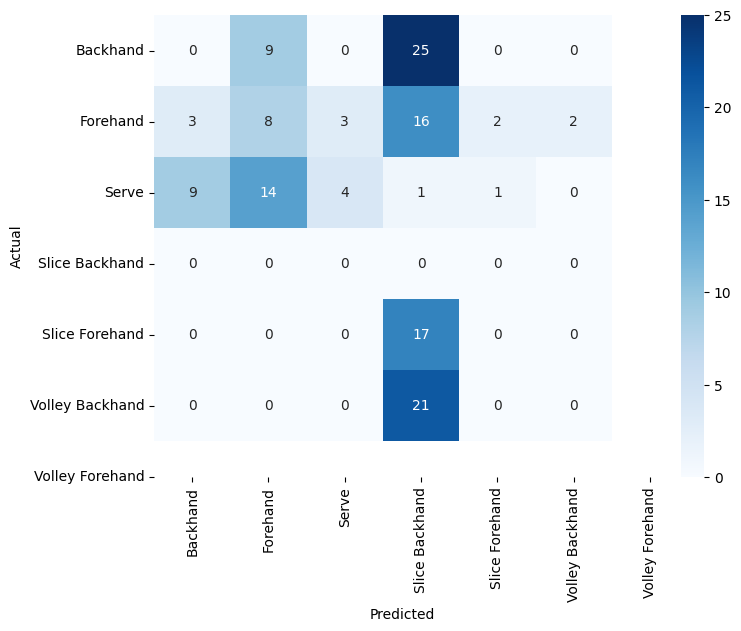

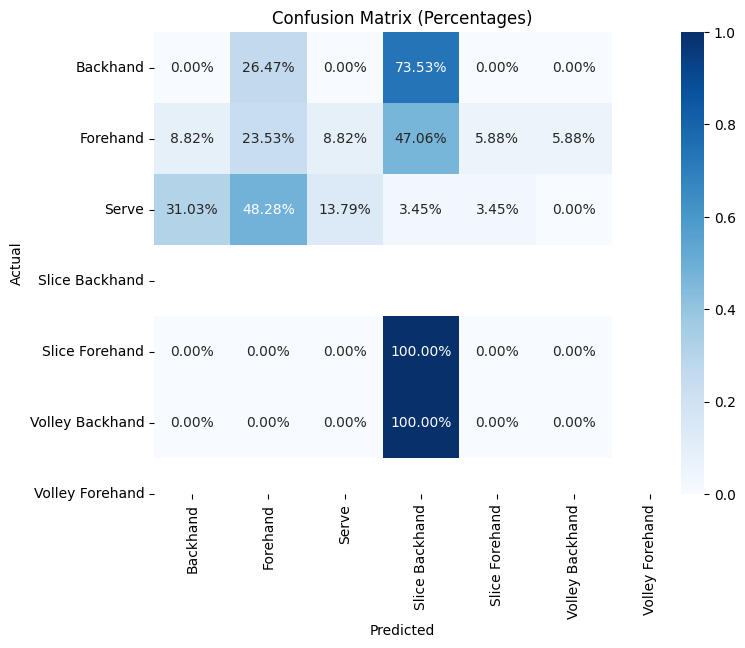

Accuracy is 8.88888888888889 %


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_72052/545270474.py:834: RuntimeWarning: invalid value encountered in divide
  confusion_mat_percent = confusion_mat / confusion_mat.sum(axis=1)[:, np.newaxis]


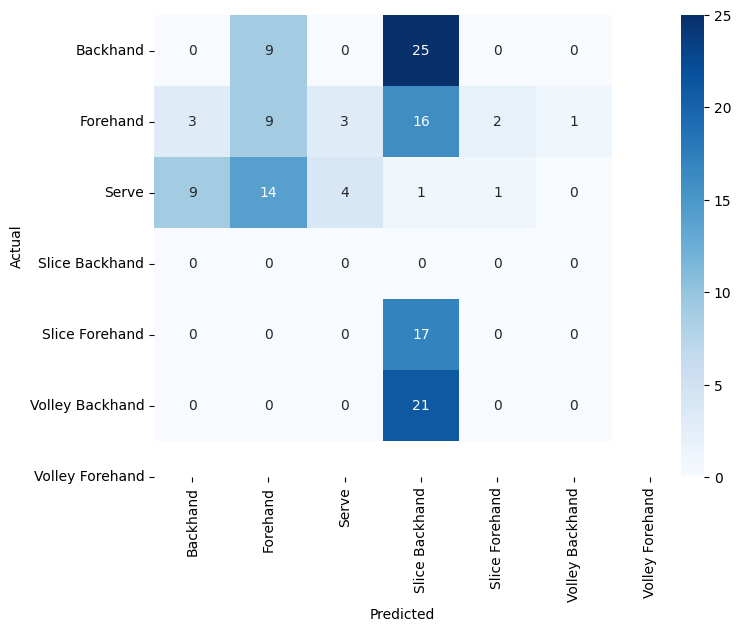

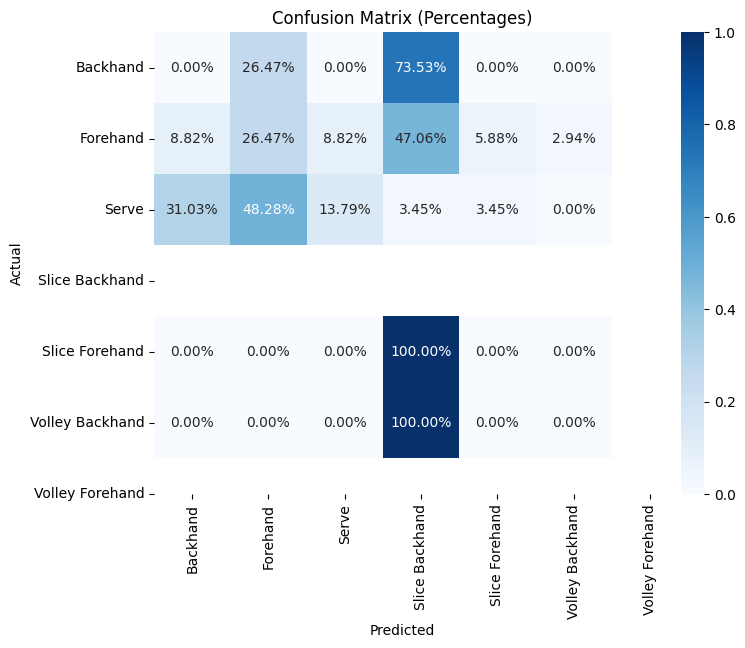

Accuracy is 9.62962962962963 %


In [62]:
# # train svm


# svm_disha =  SVC(kernel='rbf', C=5, gamma='auto', probability=True, class_weight='balanced')
# svm_disha.fit(X_train_std , y_train)
y_pred= svme.predict(X_test_std)
labels = svme.classes_
confusion_and_accuracy(y_test, y_pred, labels,'Wisdom')

# svm_nobalance_disha =  SVC(kernel='rbf', C=5, gamma='auto', probability=True)
# svm_nobalance_disha.fit(X_train_std , y_train)
y_pred= svm_nobalance.predict(X_test_std)
labels = svm_nobalance.classes_
confusion_and_accuracy(y_test, y_pred, labels,'Wisdom')


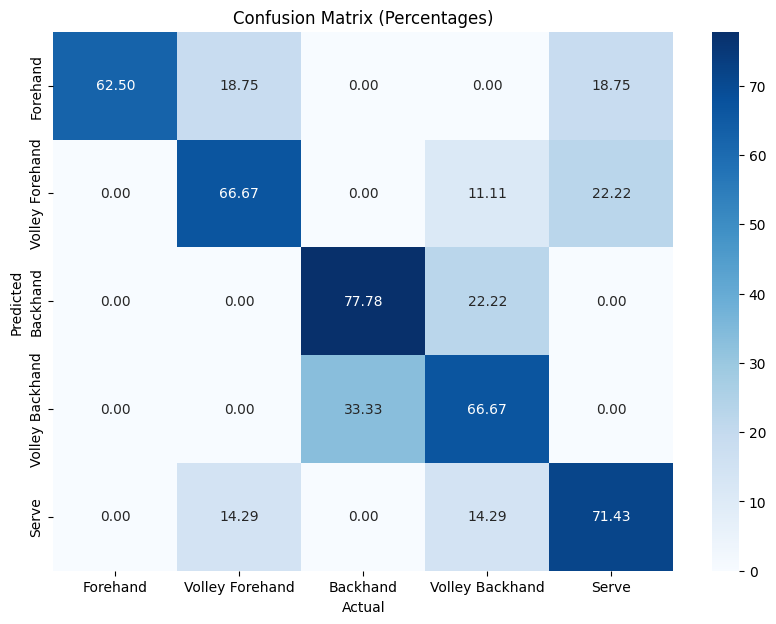

In [23]:
# # # this is testing on dishas data with svm trained from dta collected on apple watch


# svm_qual =   SVC(kernel='rbf', C=5, gamma='auto', probability=True, class_weight='balanced')
# # # svm_qual.fit(X_train_std , y_train)# Filter out 'Slice Forehand' and 'Slice Backhand'
# # mask = (t_disha.flatten() != "Slice Forehand") & (t_disha.flatten() != "Slice Backhand")
# # print(t_disha.shape)
# # print(fA_disha.shape)
# # fA_disha = fA_disha[mask,:]
# # t_disha = t_disha[mask]
# # data_disha = np.hstack((fA_disha, t_disha.reshape(-1, 1)))
# # columns = ['a_xmax','a_ymax','a_zmax','a_xmin','a_ymin','a_zmin',
# #            'a_xmean','a_ymean','a_zmean','a_xstd','a_ystd','a_zstd',
# #            'a_xarea','a_yarea','a_zarea','g_xmax','g_ymax','g_zmax',
# #            'g_xmin','g_ymin','g_zmin','g_xmean','g_ymean','g_zmean',
# #            'g_xstd','g_ystd','g_zstd','g_xarea','g_yarea','g_zarea', 'shot_type']
# # df_disha = pd.DataFrame(data_disha, columns= columns)
# # # Standardise the data
# # df_disha.iloc[:, :-1] = scaler.fit_transform(df_disha.iloc[:, :-1])
# # Apply dummy encoding from previous df to this df
# # df_disha = pd.get_dummies(df_disha, columns= ['shot_type'])
# y_pred= svm_qual.predict(df_disha)
# labels = svm_qual.classes_
# confusion_and_accuracy(["Good"]*len(y_pred),y_pred , labels,'Wisdom')

# # svm_nobalance_qual =  SVC(kernel='rbf', C=5, gamma='auto', probability=True)
# # # svm_nobalance_qual.fit(X_train_std , y_train)
# # y_pred= svm_nobalance_qual.predict(X_test_std)
# # labels = svm_nobalance_qual.classes_
# # confusion_and_accuracy(y_test, y_pred, labels,'Wisdom')

# Creating the data for the confusion matrix
data = {'Forehand': [10, 0, 0, 0, 0],
        'Volley Forehand': [3, 6, 0, 0, 1],
        'Backhand': [0, 0, 7, 3, 0],
        'Volley Backhand': [0, 1, 2, 6, 1],
        'Serve': [3, 2, 0, 0, 5]}

# Labels
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

actual = ['Forehand', 'Volley Forehand', 'Backhand','Volley Backhand', 'Serve']
predicted = ['Forehand', 'Volley Forehand', 'Backhand', 'Volley Backhand', 'Serve']


# Creating the DataFrame
df = pd.DataFrame(data, index=actual, columns=predicted)

# Calculate percentages for each class
df_percent = df.div(df.sum(axis=1), axis='index') * 100

# Plotting the confusion matrix with percentages
plt.figure(figsize=(10, 7))
sns.heatmap(df_percent, annot=True, fmt='.2f', cmap='Blues',)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion Matrix (Percentages)')
plt.show()
# 

In [96]:
# df_disha["prediction"]= y_pred
# df_disha["shot_type"]= t_disha.flatten()
# See the shot types that were predicted as alright and subpar
df_disha[df_disha["prediction"]== "Great"]["shot_type"].value_counts()


shot_type
Forehand           71
Backhand           66
Serve              32
Volley Forehand    15
Name: count, dtype: int64

/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/base.py:443: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/base.py:443: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/base.py:443: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/base.py:443: UserWarning: X has feature names, but SVC was fi

Text(0, 0.5, 'Magnitude of Importance')

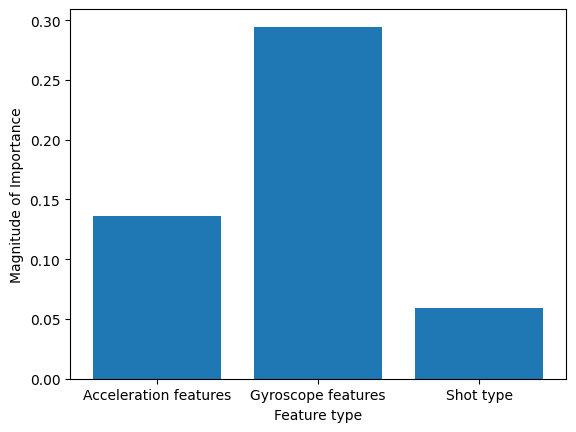

In [105]:
from sklearn.inspection import permutation_importance
# Get the permutation importance
feature_names= df_disha.columns[:-2]

perm_importance = permutation_importance(svm_qual, df_disha.iloc[:, :-2], ['Great']*len(df_disha))
sorted_idx = perm_importance.importances_mean.argsort()
# plt.barh(feature_names[sorted_idx], perm_importance.importances_mean[sorted_idx])
# plt.xlabel("Permutation Importance")
# plt.show()
# Lump encoded shot types into one and lump all gyro features into one and all accel features into one to view contribution of each to the model
# Get the permutation importance
# feature_names= df_disha.columns[:-2]
# Get the permutation importance
# perm_importance = permutation_importance(svm_qual, df_disha.iloc[:, :-2], ['Great']*len(df_disha))
# sorted_idx = perm_importance.importances_mean.argsort()
# plt.barh(feature_names[sorted_idx], perm_importance.importances_mean[sorted_idx])
lump_features= ['Acceleration features', 'Gyroscope features', 'Shot type']
df_importance= pd.DataFrame(perm_importance.importances_mean[sorted_idx], index= feature_names[sorted_idx], columns= ['Importance'])
# Filter by index string
# df_importance.loc[df_disha.columns[:-2].str.contains('a_'), 'Feature type']= 'Acceleration features'
# df_importance.loc[df_disha.columns[:-2].str.contains('g_'), 'Feature type']= 'Gyroscope features'
# df_importance.loc[df_disha.columns[:-2].str.contains('shot_type'), 'Feature type']= 'Shot type'
# Create a new column 'Feature type' based on conditions
df_importance['Feature type'] = np.where(df_importance.index.str.contains('a_'), 'Acceleration features',
                                         np.where(df_importance.index.str.contains('g_'), 'Gyroscope features', 'Shot type'))
accel_importance= abs(df_importance[df_importance['Feature type']== 'Acceleration features']['Importance']).sum()
gyro_importance= abs(df_importance[df_importance['Feature type']== 'Gyroscope features']['Importance']).sum()
shot_importance= abs(df_importance[df_importance['Feature type']== 'Shot type']['Importance']).sum()
# Plot the permutation importance
plt.figure()
plt.bar(lump_features, [accel_importance, gyro_importance, shot_importance])
plt.xlabel('Feature type')
plt.ylabel('Magnitude of Importance')





In [109]:
df_importance[df_importance['Feature type']== 'Acceleration features']['Importance']

a_zstd    -0.043553
a_xstd    -0.011461
a_xmax    -0.010315
a_zmean   -0.009169
a_zarea   -0.008596
a_ystd    -0.007450
a_ymax    -0.005731
a_zmin    -0.005158
a_ymin    -0.003438
a_yarea   -0.002292
a_xarea   -0.002292
a_xmean   -0.002292
a_ymean   -0.001719
a_zmax    -0.001719
a_xmin     0.021203
Name: Importance, dtype: float64

/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_5219/3700605132.py:35: UserWarning: The following kwargs were not used by contour: 'c'
  plt.contourf(xx, yy, Z, c=y, alpha=0.4)


([], [])

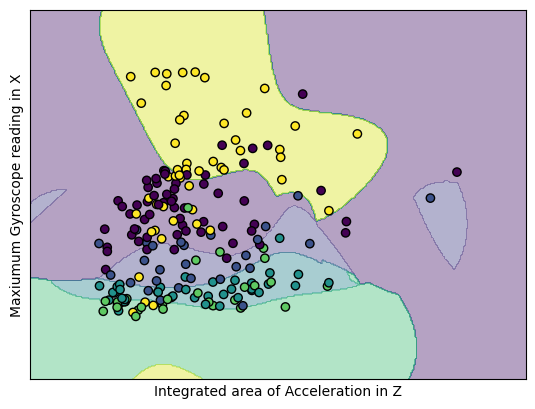

In [43]:
from sklearn.inspection import DecisionBoundaryDisplay
ax = plt.gca()
# # # Display the decision boundary for the SVM model for the first two features
# display = DecisionBoundaryDisplay.from_estimator(svm_model, X= X_test_std, ax=ax)
# display.plot()
# create a mesh to plot in
X= X_test_std[:,15:17]
# cONERT Y_TEST TO numerical encoding from the string values

y_test_num= np.zeros(len(y_test))
for i, shot in enumerate(y_test):
    if shot == 'Forehand':
        y_test_num[i]= 0
    elif shot == 'Volley Forehand':
        y_test_num[i]= 1
    elif shot == 'Backhand':
        y_test_num[i]= 2
    elif shot == 'Volley Backhand':
        y_test_num[i]= 3
    elif shot == 'Serve':
        y_test_num[i]= 4

y= y_test_num    
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
h=0.02
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

clf = SVC(kernel='rbf', C=50, gamma='auto').fit(X, y)
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, c=y, alpha=0.4)

# Plot also the training points
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k')
plt.xlabel('Integrated area of Acceleration in Z')
plt.ylabel('Maxiumum Gyroscope reading in X')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xticks(())
plt.yticks(())
# Legend for the plotted colpours

# plt.title(titles[i])

In [1]:


# pca analysis
pcae = PCA().fit(X_train_std)
plt.plot(np.cumsum(pcae.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
pcae.n_components_

NameError: name 'PCA' is not defined

In [10]:
# K Fold Cross Validation 


n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True)

# Array for various C values
C_array = np.array([1])
# C_array = np.linspace(1,20,20)
print(C_array)
nC = len(C_array)

# Creating array for test and train accuracies for the various C values
test_cor_array = np.zeros([nC,1])
train_cor_array = np.zeros([nC,1])


# for cCnt in range(nC):
X= fA
y= t_1
    
tot_correct_fraction_test = 0
tot_correct_fraction_train = 0
    
for train_index, test_index in kf.split(X):
    stdsc = StandardScaler()
    X_train = stdsc.fit_transform(X[train_index])
    y_train = y[train_index]
    X_test = stdsc.transform(X[test_index])
    y_test = y[test_index]

    #use X_train, y_train to train the SVM
    svm = SVC(C=5, gamma='auto', kernel='rbf')

    svm.fit(X_train,y_train)

    #use svm.predict() to predict the output for the test data set
    y_test_model = svm.predict(X_test)

    #loop through to compare the test data output to what it should be and obtain the fraction of correct classifications
    nTot = len(y_test) 
    nMatch = 0 
    for i in range(len(y_test)):
        if y_test[i] == y_test_model[i]:
            nMatch += 1

    correct_fraction_test = nMatch / nTot

    #do the same prediction and performance assessment performance with the training data
    y_train_model = svm.predict(X_train)

    nTot = len(y_train) 
    nMatch = 0
    for i in range(len(y_train)):
        if y_train[i] == y_train_model[i]:
            nMatch += 1

    correct_fraction_train = nMatch / nTot

    # add on to the totals
    tot_correct_fraction_test += correct_fraction_test
    tot_correct_fraction_train += correct_fraction_train

print('Correct percentage for test data: ', 100*tot_correct_fraction_test/n_splits)
print('Correct percentage for training data: ', 100*tot_correct_fraction_train/n_splits)
  
    # test_cor_array[cCnt] = 100*tot_correct_fraction_test/n_splits
    # train_cor_array[cCnt] = 100*tot_correct_fraction_train/n_splits  


# plt.figure()
# line_train, = plt.plot(C_array,train_cor_array,'k--', label = 'Training data')
# line_test, = plt.plot(C_array,test_cor_array,'r-',label='Test data')
# #line_train, = plt.semilogx(C_array,train_cor_array,'k--', label = 'Training data')
# #line_test, = plt.semilogx(C_array,test_cor_array,'r-',label='Test data')
# plt.xlabel('C')
# plt.ylabel('Percentage correct')
# plt.legend(handles=[line_test, line_train])

[1]
Correct percentage for test data:  97.33333333333333
Correct percentage for training data:  99.66666666666666


/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:1111: DataConversionWarning: A column-vector y was passed when a 1d array was expe

In [69]:
X= fA
y= t_1
    
tot_correct_fraction_test = 0
tot_correct_fraction_train = 0
class_correct_fraction_test = np.zeros((5,1))
class_correct_fraction_train = np.zeros((5,1))
for train_index, test_index in kf.split(X):
    stdsc = StandardScaler()
    X_train = X[train_index]
    y_train = y[train_index]
    X_test = X[test_index]
    y_test = y[test_index]

    #use X_train, y_train to train the SVM
    clf = ensemble.RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=1, min_samples_split=2, bootstrap=False)

    clf.fit(X_train,y_train)

    #use svm.predict() to predict the output for the test data set
    y_test_model = clf.predict(X_test)

    #loop through to compare the test data output to what it should be and obtain the fraction of correct classifications
    nTot = len(y_test) 
    nMatch = 0 
    for i in range(len(y_test)):
        if y_test[i] == y_test_model[i]:
            nMatch += 1

    correct_fraction_test = nMatch / nTot

    #do the same prediction and performance assessment performance with the training data
    y_train_model = clf.predict(X_train)

    nTot = len(y_train) 
    nMatch = 0
    for i in range(len(y_train)):
        if y_train[i] == y_train_model[i]:
            nMatch += 1
    correct_fraction_train = nMatch / nTot
    # Also calculate teh accuracy for each class
    labels = clf.classes_
    for i in range(5):
        nTot = len(y_train[y_train == labels[i]])
        nMatch = 0
        for j in range(len(y_train)):
            if y_train[j] == labels[i] and y_train_model[j] == labels[i]:
                nMatch += 1
        class_correct_fraction_train[i] += nMatch / nTot
    print(class_correct_fraction_train)
    for i in range(5):
        nTot = len(y_test[y_test == labels[i]])
        nMatch = 0
        for j in range(len(y_test)):
            if y_test[j] == labels[i] and y_test_model[j] == labels[i]:
                nMatch += 1
        class_correct_fraction_test[i] += nMatch / nTot
    print(class_correct_fraction_test)
    

    # add on to the totals
    tot_correct_fraction_test += correct_fraction_test
    tot_correct_fraction_train += correct_fraction_train
    class_correct_fraction_test += class_correct_fraction_test
    class_correct_fraction_train += class_correct_fraction_train
    print(clf.classes_)

print('Correct percentage for test data: ', 100*tot_correct_fraction_test/n_splits)
print('Correct percentage for training data: ', 100*tot_correct_fraction_train/n_splits)
print('Correct percentage for each class in test data: ', 100*np.array(class_correct_fraction_test)/n_splits)
print('Correct percentage for each class in training data: ', 100*np.array(class_correct_fraction_train)/n_splits)


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_5219/3413277591.py:18: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  clf.fit(X_train,y_train)
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/ensemble/_forest.py:427: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(
/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_5219/3413277591.py:18: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  clf.fit(X_train,y_train)
/Users/wisdom/

[[1.]
 [1.]
 [1.]
 [1.]
 [1.]]
[[0.95238095]
 [0.97560976]
 [1.        ]
 [0.92592593]
 [0.83333333]]
['Backhand' 'Forehand' 'Serve' 'Volley Backhand' 'Volley Forehand']
[[3.]
 [3.]
 [3.]
 [3.]
 [3.]]
[[2.87027915]
 [2.88670338]
 [2.875     ]
 [2.80185185]
 [2.57971014]]
['Backhand' 'Forehand' 'Serve' 'Volley Backhand' 'Volley Forehand']


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_5219/3413277591.py:18: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  clf.fit(X_train,y_train)
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/ensemble/_forest.py:427: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(
/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_5219/3413277591.py:18: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  clf.fit(X_train,y_train)
/Users/wisdom/

[[7.]
 [7.]
 [7.]
 [7.]
 [7.]]
[[6.74055829]
 [6.72896232]
 [6.72058824]
 [6.4037037 ]
 [6.05415713]]
['Backhand' 'Forehand' 'Serve' 'Volley Backhand' 'Volley Forehand']
[[15.]
 [15.]
 [15.]
 [15.]
 [15.]]
[[14.48111658]
 [14.42344189]
 [14.44117647]
 [13.80740741]
 [13.06285972]]
['Backhand' 'Forehand' 'Serve' 'Volley Backhand' 'Volley Forehand']
[[31.]
 [31.]
 [31.]
 [31.]
 [31.]]
[[29.93520614]
 [29.75010958]
 [29.81783681]
 [28.53789174]
 [26.95180639]]
['Backhand' 'Forehand' 'Serve' 'Volley Backhand' 'Volley Forehand']
Correct percentage for test data:  94.66666666666666
Correct percentage for training data:  100.0
Correct percentage for each class in test data:  [[1197.40824568]
 [1190.00438307]
 [1192.71347249]
 [1141.51566952]
 [1078.07225574]]
Correct percentage for each class in training data:  [[1240.]
 [1240.]
 [1240.]
 [1240.]
 [1240.]]


/var/folders/dd/v56x53yx5bzb_42xkxpb3zx80000gp/T/ipykernel_5219/3413277591.py:18: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  clf.fit(X_train,y_train)
/Users/wisdom/Library/CloudStorage/OneDrive-ImperialCollegeLondon/uni/FYP-DESKTOP-27I1PBE/FYP--WIsdom/Disha Redo/.venv/lib/python3.10/site-packages/sklearn/ensemble/_forest.py:427: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(


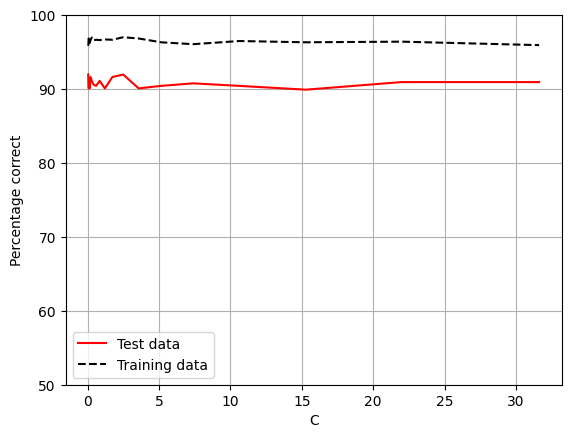

In [ ]:
plt.figure()
line_train, = plt.plot(C_array,train_cor_array,'k--', label = 'Training data')
line_test, = plt.plot(C_array,test_cor_array,'r-',label='Test data')
plt.xlabel('C')
plt.ylim([50,100])
plt.ylabel('Percentage correct')
plt.legend(handles=[line_test, line_train])
plt.grid()


In [ ]:
param_grid = {'C': [0.1,1, 10, 100,1000], 'gamma': [1,0.1,0.01,0.001],'kernel': ['rbf', 'poly', 'sigmoid']}
grid = GridSearchCV(SVC(),param_grid,refit=True,verbose=2,scoring='balanced_accuracy')
grid.fit(X_train_std,y_train)
# lag_inexperienced= lag
print(grid.best_estimator_)
grid_predictions = grid.predict(X_test_std)
print(confusion_matrix(y_test,grid_predictions))

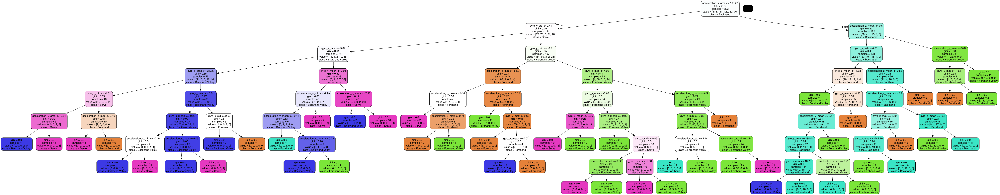

In [34]:
#  Visualise decision tree fromr andom forest
from sklearn.tree import export_graphviz
import pydotplus
from IPython.display import Image
import matplotlib.image as mpimg
# Extract single tree
estimator = randnew_apple.estimators_[5]
# Export as dot file
dotdata= export_graphviz(estimator, out_file='newdot.dot', 
                feature_names = ['acceleration_x_max','acceleration_y_max','acceleration_z_max','acceleration_x_min','acceleration_y_min','acceleration_z_min','acceleration_x_mean','acceleration_y_mean','acceleration_z_mean','acceleration_x_std','acceleration_y_std','acceleration_z_std','acceleration_x_area','acceleration_y_area','acceleration_z_area','gyro_x_max','gyro_y_max','gyro_z_max','gyro_x_min','gyro_y_min','gyro_z_min','gyro_x_mean','gyro_y_mean','gyro_z_mean','gyro_x_std','gyro_y_std','gyro_z_std','gyro_x_area','gyro_y_area','gyro_z_area'],
                class_names = ['Forehand','Forehand Volley','Backhand','Backhand Volley ','Serve'],
                rounded = True, proportion = False, precision = 2, filled = True)
# Show as image 

graph = pydotplus.graph_from_dot_file('newdot.dot')
# graph.write_pdf('tree.pdf')
Image(graph.create_png())
# img = mpimg.imread(io.BytesIO(png_data))
# # Plot the image using matplotlib
# plt.imshow(img)
# plt.axis('off')  # Hide the axes
# plt.show()

